In [5]:
# ============================================================
# 0. 依赖 / 全局配置 / 输出目录
# ============================================================
import os, sys, json, math, time, warnings, platform
from pathlib import Path
from datetime import datetime

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.interpolate import PchipInterpolator
import torch
import torch.nn as nn
warnings.filterwarnings("ignore")

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "SimSun", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=[
    "#2f6fb3", "#d1495b", "#2a9d8f", "#e9a13b", "#7b5ea7", "#5f8c4a", "#8d6e63", "#546e7a"])

# 路径
DESKTOP   = Path.home() / "Desktop"
DATA_PATH = DESKTOP / "测试集.csv"
BASE_DIR  = DESKTOP / "电池ai分析"
FULL_DATA_CANDIDATES = [
    BASE_DIR / "IEEE2014DataChallengeData" / "IEEE 2014 Data Challenge Data" / "FC1_Without_Ripples" / "FC1.csv",
    DESKTOP / "FC1.csv",
]
OUT_DIR = BASE_DIR / "预测输出"
FIG_DIR = OUT_DIR / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 时间网格与切分
DT          = 0.01                    #重采样，0.01h
SEG_H       = 50.0                    #50 h 切分
SEG_STEPS   = int(round(SEG_H / DT))  #5000 步
SMOOTH_WIN_H = 10.0                   #主曲线平滑窗（去高频噪声、保留可逆性波动）
SMOOTH_WIN_STEPS = int(round(SMOOTH_WIN_H / DT))     # 1001 步（奇数，居中）
TREND_WIN_H = 150.0                   # 面积基准用的低通趋势窗（≈3 个 50h 窗口）
TREND_WIN_STEPS = int(round(TREND_WIN_H / DT))       # 15001 步

# GRU 模型 / 训练
SEQ          = 50            #滑动窗口长度
EPOCHS       = 20            #20 轮
BATCH        = 4096          #每次喂给网络的数量
HIDDEN       = 64            #神经细胞数量
N_LAYERS     = 1             #层数
LR           = 2e-3          #学习率（learning rate）
WEIGHT_DECAY = 1e-5
GRAD_CLIP    = 1.0
VAL_FRAC     = 0.08          # 末尾 8% 做验证（时间顺序切分）
TIME_FEATURE_GAIN = 3.0      # 时间特征放大倍数（"时间特征强化"）
LAMBDA_TIME  = 0.30          # "时间越长 |ΔU| 越小" 弱正则权重

# 外推
T_EXTRAP        = 920.0       # 外推起点（h）。数据实际末点 ≈912.85 h，见下方说明
N_STEPS_EXTRAP  = 100_000     # 10 万步 = 1000 h
N_WIN_HIST      = 6           # 历史最后 6 个 5000 步窗口 → 零点基准面积
W_PHYS, W_AI    = 0.8, 0.2    # 80% 物理 + 20% AI
ALLOW_AI_RIPPLE = False       # True 则交付曲线=骨架+20%AI高频纹波（会违反曲率硬约束，仅对照用）
DELIVER_POINTWISE = False     # True 则交付曲线取"逐点 0.8·物理+0.2·AI"；
                              # False 则交付"面积层带内融合"（严格满足全部约束，默认）
AR_CLIP_SIGMA   = 5.0         # 自回归单步增量截断（数值安全，非物理约束）

# RUL（IEEE PHM 2014 Data Challenge 的 5 个功率衰减阈值）
RUL_FT          = [3.5, 4.0, 4.5, 5.0, 5.5]   # % of initial power
P_INIT_H        = 10.0        # 初始功率，前 10 h 的平均功率
CROSS_DEBOUNCE_H = 5.0        # 阈值穿越去抖：需持续 5 h 低于阈值
BT_ORIGIN_H     = 660.0       # 盲测回填验证：以 660 h 为起点重跑全流程
RUN_BACKTEST    = True        # 是否运行第 10 节的盲测回填（会多训练一个模型，约 5 分钟）
RUN_FC2_VALIDATION = False    # 是否用 FC2 整段记录做跨堆栈 RUL 验证（可选，见末节）

# 调试模式：环境变量 BATT_SMOKE=1 时只跑 2 轮 + 1.5 万步，用于快速排错
SMOKE = bool(int(os.environ.get("BATT_SMOKE", "0")))
if SMOKE:
    EPOCHS, N_STEPS_EXTRAP = 2, 15_000
N_WIN_FUTURE = N_STEPS_EXTRAP // SEG_STEPS          # 未来窗口数（正式=20）
assert N_WIN_FUTURE >= 3, "外推步数至少 3 个完整窗口"

# 全局种子 & 设备
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(8, os.cpu_count() or 4)))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def savefig(fig, name: str, show=True):
    """保存图片到 预测输出/figures/ 并可选内联显示。"""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=140)
    if show:
        plt.show()
    return path

def seed_everything(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

print("=" * 78)
print(f"运行环境 : Python {platform.python_version()} | torch {torch.__version__} | 设备 {DEVICE}")
print(f"数据文件 : {DATA_PATH}")
print(f"输出目录 : {OUT_DIR}")
print(f"模式     : {'SMOKE 调试' if SMOKE else '正式'} | EPOCHS={EPOCHS} | 外推步数={N_STEPS_EXTRAP:,} | 未来窗口数={N_WIN_FUTURE}")
print("=" * 78)

运行环境 : Python 3.9.25 | torch 2.5.1 | 设备 cpu
数据文件 : C:\Users\YOGA\Desktop\测试集.csv
输出目录 : C:\Users\YOGA\Desktop\电池ai分析\预测输出
模式     : 正式 | EPOCHS=20 | 外推步数=100,000 | 未来窗口数=20


In [6]:
# ============================================================
# 1. 数据读取 → 均匀重采样 → 平滑（主曲线 + 趋势曲线）
# ============================================================
def load_and_prepare(csv_path: Path, dt: float = DT, smooth_win_steps: int = SMOOTH_WIN_STEPS):
    """读取 CSV，线性插值到 dt 网格，生成 10h 平滑主曲线与 150h 低通趋势曲线。"""
    df = pd.read_csv(csv_path)
    df.columns = [str(c).strip() for c in df.columns]
    need = ["Time (h)", "Utot (V)", "I (A)", "TinAIR (°C)", "HrAIRFC (%)"]
    miss = [c for c in need if c not in df.columns]
    if miss:
        raise KeyError(f"{csv_path} 缺少列: {miss}; 实际列 = {list(df.columns)[:10]}...")

    t_raw = df["Time (h)"].to_numpy(float)
    t_end = float(t_raw.max())
    grid = np.arange(0.0, t_end + 1e-9, dt)

    out = dict(t=grid, t_end=t_end, n_raw=len(df), n_nan=int(df[need].isna().sum().sum()),
               dt_raw_median=float(np.median(np.diff(t_raw))), path=str(csv_path))
    out["u_raw"] = np.interp(grid, t_raw, df["Utot (V)"].to_numpy(float))

    for key, col in [("I", "I (A)"), ("T", "TinAIR (°C)"), ("RH", "HrAIRFC (%)")]:
        raw = np.interp(grid, t_raw, df[col].to_numpy(float))
        out[key + "_raw"] = raw
        out[key + "_s"] = (pd.Series(raw).rolling(smooth_win_steps, center=True, min_periods=1)
                           .mean().to_numpy())

    out["u_s"] = (pd.Series(out["u_raw"]).rolling(smooth_win_steps, center=True, min_periods=1)
                  .mean().to_numpy())
    # 150 h 低通趋势：只用于"面积基准"，把可逆性波动当噪声压掉
    tr = (pd.Series(out["u_s"]).rolling(TREND_WIN_STEPS, center=True,
                                        min_periods=TREND_WIN_STEPS // 3)
          .mean().to_numpy())
    out["u_trend"] = pd.Series(tr).bfill().ffill().to_numpy()
    return out


data = load_and_prepare(DATA_PATH)
t      = data["t"]
u_raw  = data["u_raw"]
u_s    = data["u_s"]
u_trend = data["u_trend"]
I_s, T_s, RH_s = data["I_s"], data["T_s"], data["RH_s"]
N        = len(t)
t_end    = data["t_end"]          # = 912.8478 h
u_anchor = float(u_s[-1])         # 外推锚点电压

print(f"原始记录   : {data['n_raw']:,} 行, 0 ~ {t_end:.4f} h, 原始采样间隔中位数 {data['dt_raw_median']:.5f} h, 缺失值 {data['n_nan']}")
print(f"均匀网格   : N = {N:,} 点, dt = {DT} h, 50h 窗口 = {SEG_STEPS} 步")
print(f"电压(10h)  : 起点 {u_s[0]:.4f} V → 终点 {u_anchor:.4f} V (总降 {(u_s[0]-u_anchor)*1000:.2f} mV)")
print(f"电压(原始) : min {u_raw.min():.4f} / max {u_raw.max():.4f} V")
print(f"可逆性波动 : max|u_s - u_trend| = {np.max(np.abs(u_s - u_trend))*1000:.2f} mV"
      f"（发生在 {t[np.argmax(np.abs(u_s - u_trend))]:.1f} h）→ 远大于总衰减，说明必须做物理定标")
print(f"工作电流   : 中位数 {np.median(I_s):.2f} A（标称 70 A = 0.70 A/cm² × 100 cm²）")
assert abs(t_end - 912.8478233) < 0.01, "数据末端时间与预期不符，请检查文件"

# ---------------- RUL 判定阈值（IEEE PHM 2014 Data Challenge 定义） ----------------
I_REF = float(np.median(I_s[-1000:]))                       # 未来工况未知 → 电流 persistence
P_INIT = float(np.mean(u_s[:int(P_INIT_H / DT)] * I_s[:int(P_INIT_H / DT)]))
RUL_FT_ = list(RUL_FT)
RUL_UTH = [P_INIT * (1 - f / 100.0) / I_REF for f in RUL_FT_]
print(f"\nRUL 判定: P_init = {P_INIT:.3f} W（前 {P_INIT_H:.0f} h 平均功率）, I_ref = {I_REF:.3f} A")
print("          FT(%)  电压阈值 U_th(V)")
for f, uth in zip(RUL_FT_, RUL_UTH):
    print(f"          {f:5.1f}  {uth:12.5f}   （当前 {u_anchor:.5f} V, 距阈值 {(u_anchor-uth)*1e3:+.2f} mV）")

原始记录   : 115,077 行, 0 ~ 912.8478 h, 原始采样间隔中位数 0.00839 h, 缺失值 0
均匀网格   : N = 91,285 点, dt = 0.01 h, 50h 窗口 = 5000 步
电压(10h)  : 起点 3.3455 V → 终点 3.2206 V (总降 124.92 mV)
电压(原始) : min 3.0970 / max 3.3640 V
可逆性波动 : max|u_s - u_trend| = 30.97 mV（发生在 816.0 h）→ 远大于总衰减，说明必须做物理定标
工作电流   : 中位数 70.23 A（标称 70 A = 0.70 A/cm² × 100 cm²）

RUL 判定: P_init = 235.060 W（前 10 h 平均功率）, I_ref = 70.202 A
          FT(%)  电压阈值 U_th(V)
            3.5       3.23114   （当前 3.22063 V, 距阈值 -10.51 mV）
            4.0       3.21440   （当前 3.22063 V, 距阈值 +6.23 mV）
            4.5       3.19766   （当前 3.22063 V, 距阈值 +22.97 mV）
            5.0       3.18091   （当前 3.22063 V, 距阈值 +39.72 mV）
            5.5       3.16417   （当前 3.22063 V, 距阈值 +56.46 mV）


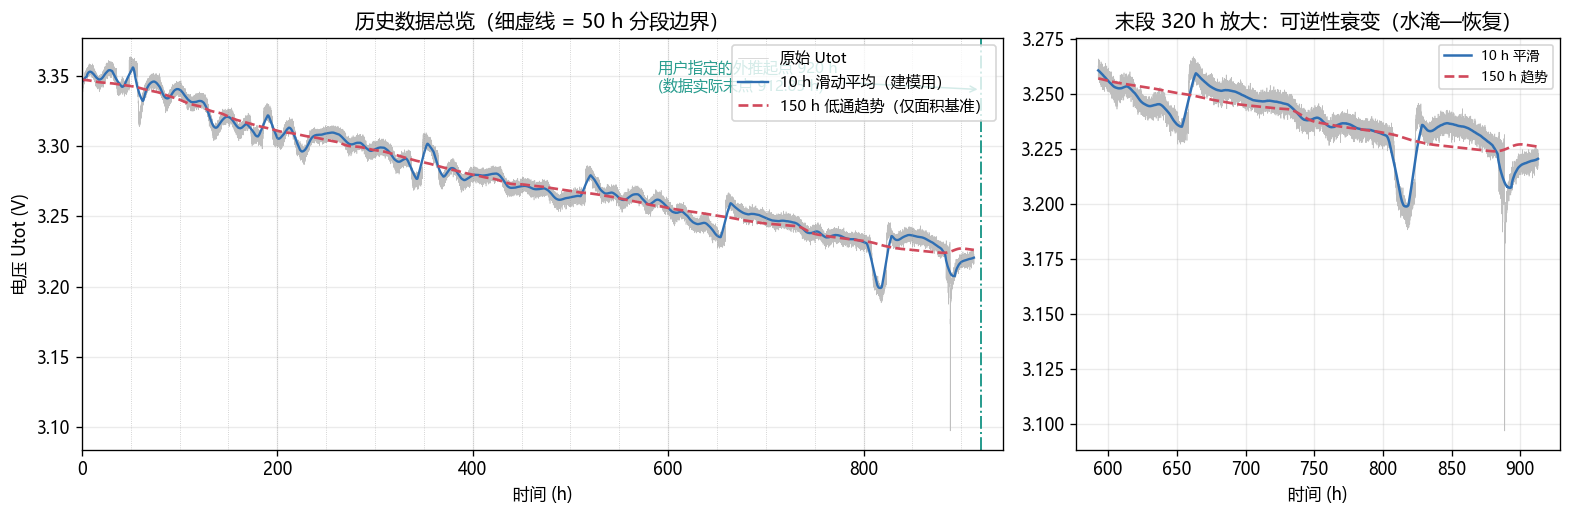

已保存: C:\Users\YOGA\Desktop\电池ai分析\预测输出\figures\fig01_历史数据总览.png


In [7]:
# ------------------------------------------------
# 图 1：历史数据总览（原始 / 10h 平滑 / 150h 趋势）
# ------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.4),
                         gridspec_kw=dict(width_ratios=[2.0, 1.05]))
ax = axes[0]
ax.plot(t, u_raw, lw=0.35, color="0.75", label="原始 Utot")
ax.plot(t, u_s, lw=1.4, color="#2f6fb3", label="10 h 滑动平均（建模用）")
ax.plot(t, u_trend, lw=1.6, ls="--", color="#d1495b", label="150 h 低通趋势（仅面积基准）")
for k in range(0, int(t_end // SEG_H) + 1):
    ax.axvline(k * SEG_H, color="0.6", lw=0.5, ls=":", alpha=0.55)
ax.axvline(T_EXTRAP, color="#2a9d8f", lw=1.2, ls="-.")
ax.annotate(f"用户指定的外推起点 {T_EXTRAP:.0f} h\n(数据实际末点 {t_end:.2f} h)",
            xy=(T_EXTRAP, u_s[0] - 0.005), xytext=(T_EXTRAP - 330, u_s[0] - 0.006),
            fontsize=9, color="#2a9d8f",
            arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=0.9))
ax.set_xlabel("时间 (h)"); ax.set_ylabel("电压 Utot (V)")
ax.set_title("历史数据总览（细虚线 = 50 h 分段边界）")
ax.legend(loc="upper right", fontsize=9); ax.set_xlim(0, t_end + 30)

ax = axes[1]
sl = t > t_end - 320
ax.plot(t[sl], u_raw[sl], lw=0.4, color="0.75")
ax.plot(t[sl], u_s[sl], lw=1.5, color="#2f6fb3", label="10 h 平滑")
ax.plot(t[sl], u_trend[sl], lw=1.6, ls="--", color="#d1495b", label="150 h 趋势")
ax.set_xlabel("时间 (h)"); ax.set_title("末段 320 h 放大：可逆性衰变（水淹—恢复）")
ax.legend(fontsize=8)

fig.tight_layout()
fig1_path = savefig(fig, "fig01_历史数据总览")
print("已保存:", fig1_path)

In [11]:
# ============================================================
# 2. 特征工程 / 滑动窗口 / GRU 模型 / 时间法则损失 / 训练
# ============================================================
def _time_cols(ti, t_ref, gain=TIME_FEATURE_GAIN):
    """四种时间表示（ti, t_ref 单位 h）。倒数型与对数型在 t→∞ 时不发散，便于外推。"""
    ti = np.asarray(ti, dtype=np.float64)
    return (ti / t_ref,
            2.0 * ti / (ti + t_ref),
            gain * ti / t_ref,
            np.log1p(ti) / math.log1p(t_ref))


def feature_matrix(u, I, T, RH, t_arr, t_ref, gain=TIME_FEATURE_GAIN, stats=None):
    """构造 (N,10) 特征矩阵。stats 传入时复用其归一化参数（外推时必须复用，避免漂移）。"""
    u = np.asarray(u, float); t_arr = np.asarray(t_arr, float)
    if stats is None:
        stats = {"u_bar": float(np.mean(u)), "u_scale": 0.05}
        for k, v in (("I", I), ("T", T), ("RH", RH)):
            v = np.asarray(v, float)
            stats[k + "_mu"], stats[k + "_sd"] = float(np.mean(v)), max(float(np.std(v)), 1e-9)
        for k, v in (("dI", np.gradient(np.asarray(I, float), DT)),
                     ("dT", np.gradient(np.asarray(T, float), DT))):
            stats[k + "_mu"], stats[k + "_sd"] = float(np.mean(v)), max(float(np.std(v)), 1e-9)

    def z(key, v):
        return (np.asarray(v, float) - stats[key + "_mu"]) / stats[key + "_sd"]

    tau, tau_rec, tau_gain, logtau = _time_cols(t_arr, t_ref, gain)
    cols = [(u - stats["u_bar"]) / stats["u_scale"], tau, tau_rec, tau_gain, logtau,
            z("I", I), z("T", T), z("RH", RH),
            z("dI", np.gradient(np.asarray(I, float), DT)),
            z("dT", np.gradient(np.asarray(T, float), DT))]
    stats["t_ref"] = float(t_ref)          # 外推时复用同一时间尺度
    stats["gain"] = float(gain)
    return np.stack(cols, axis=1).astype(np.float32), stats


def build_windows(F, u, t_arr, seq=SEQ):
    """滑窗：(M,seq,10) 特征 → 下一步归一化增量标签。按时间顺序，无未来泄漏。"""
    M = len(F) - seq
    X = np.lib.stride_tricks.sliding_window_view(F, seq, axis=0)[:M]        # (M,10,seq) 视图
    X = np.ascontiguousarray(X.transpose(0, 2, 1))                          # (M,seq,10)
    du = np.diff(np.asarray(u, float))
    sig = float(np.std(du[:M])) or 1.0
    y = (du[seq - 1:M + seq - 1] / sig).astype(np.float32)
    tau_out = np.asarray(t_arr, float)[seq - 1:M + seq - 1].astype(np.float32)  # 末点时间
    return X, y, tau_out, sig


class GRUNet(nn.Module):
    """GRU + 物理感知输出头：ΔU = tanh(gate)·exp(a) + ΔU₀·tanh(log(1+t/τ))。

    最后一项是"时间越长、衰减越大"的结构先验（初始斜率不为 0，且随 t 平滑饱和），
    网络本身只需学习围绕它的波动，避免外推一开始就掉进"零斜率平线"。
    """

    def __init__(self, n_feat=10, hidden=HIDDEN, n_layers=N_LAYERS, init_du=0.5, t_scale_h=N_STEPS_EXTRAP * DT):
        super().__init__()
        self.emb = nn.Sequential(nn.Linear(n_feat, hidden), nn.LayerNorm(hidden), nn.GELU())
        self.gru = nn.GRU(hidden, hidden, n_layers, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.GELU(), nn.Linear(hidden, 2))
        with torch.no_grad():                      # 输出头小初始化 → 训练初期输出≈0，稳定
            self.head[-1].weight.mul_(0.01)
            self.head[-1].bias.zero_()
        self.du0 = nn.Parameter(torch.tensor(float(init_du)))
        self.t_scale = float(t_scale_h)

    def forward(self, x, t_last):
        h = self.emb(x)
        out, _ = self.gru(h)
        z = self.head(out[:, -1, :])
        du = torch.tanh(z[:, 0]) * torch.exp(torch.clamp(z[:, 1], -4.0, 2.0))
        du = du + self.du0 * torch.tanh(torch.log1p(torch.as_tensor(t_last, dtype=du.dtype) / self.t_scale))
        return du


def time_rule_loss(du_pred, tau, n_pairs=2048):
    """时间法则正则：时间更晚的样本，其 |ΔU| 不应更大（即 |斜率| 随 t 单调不增）。"""
    B = du_pred.shape[0]
    if B < 16:
        return du_pred.new_zeros(())
    i = torch.randint(0, B, (n_pairs,), device=du_pred.device)
    j = torch.randint(0, B, (n_pairs,), device=du_pred.device)
    dt = tau[j] - tau[i]
    mask = dt > 0.03 * tau.max()
    if mask.sum() < 8:
        return du_pred.new_zeros(())
    return torch.relu(du_pred[j][mask].abs() - du_pred[i][mask].abs()).mean()


def predict_du(model, X, tau, batch=8192):
    """批量推理：返回归一化增量（numpy）。"""
    model.eval()
    outs = []
    with torch.no_grad():
        for s in range(0, len(X), batch):
            xb = torch.from_numpy(X[s:s + batch]).to(DEVICE)
            tb = torch.from_numpy(np.asarray(tau[s:s + batch], np.float32)).to(DEVICE)
            outs.append(model(xb, tb).cpu().numpy())
    return np.concatenate(outs)


def train_model(X, y, tau, sig, epochs=EPOCHS, batch=BATCH, lr=LR, seed=SEED, verbose=True):
    """时间顺序切分训练/验证；Adam + 余弦退火；返回最优模型与训练日志。"""
    torch.manual_seed(seed)
    n = len(X)
    n_val = max(SEQ, int(n * VAL_FRAC))
    n_tr = n - n_val
    Xtr, ytr, ttr = (torch.from_numpy(np.ascontiguousarray(X[:n_tr])),
                     torch.from_numpy(y[:n_tr]), torch.from_numpy(tau[:n_tr]))
    Xva, yva, tva = (torch.from_numpy(np.ascontiguousarray(X[n_tr:])),
                     torch.from_numpy(y[n_tr:]), torch.from_numpy(tau[n_tr:]))

    init_du = float(np.median(np.abs(y[:n_tr]))) or 0.1
    model = GRUNet(init_du=init_du).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=lr * 0.02)
    mse = nn.MSELoss()

    log = dict(train=[], val=[], train_rmse_mV=[], val_rmse_mV=[], sec=[], best_epoch=0)
    best = float("inf")
    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        perm = torch.randperm(n_tr)
        tot = 0.0
        for s in range(0, n_tr, batch):
            idx = perm[s:s + batch]
            xb, yb, tb = Xtr[idx].to(DEVICE), ytr[idx].to(DEVICE), ttr[idx].to(DEVICE)
            pred = model(xb, tb)
            loss = mse(pred, yb) + LAMBDA_TIME * time_rule_loss(pred, tb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
            tot += float(loss) * len(idx)
        sched.step()
        model.eval()
        with torch.no_grad():
            pv = model(Xva.to(DEVICE), tva.to(DEVICE))
            vloss = float(mse(pv, yva.to(DEVICE)))
        tr_loss, va_rmse = tot / n_tr, math.sqrt(vloss) * sig * 1e3   # mV/步
        log["train"].append(tr_loss); log["val"].append(vloss)
        log["train_rmse_mV"].append(math.sqrt(tr_loss) * sig * 1e3); log["val_rmse_mV"].append(va_rmse)
        log["sec"].append(time.time() - t0)
        if vloss < best:
            best, log["best_epoch"] = vloss, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"epoch {ep:2d}/{epochs} | train {tr_loss:8.4f} | val {vloss:8.4f} "
                  f"| val RMSE {va_rmse:7.3f} mV/步 | lr {opt.param_groups[0]['lr']:.2e} "
                  f"| {log['sec'][-1]:5.1f}s")
    model.load_state_dict(best_state)
    log["init_du"] = init_du
    log["n_train"], log["n_val"] = n_tr, n_val
    if verbose:
        print(f"最优 epoch = {log['best_epoch']}，验证 RMSE = {log['val_rmse_mV'][log['best_epoch']-1]:.3f} mV/步")
    return model, log


# ---------------- 主历史上的特征与窗口 ----------------
u_ref = u_s                                   # 建模主曲线（10h 平滑）
FEATS, FEAT_STATS = feature_matrix(u_ref, I_s, T_s, RH_s, t, t_end)
X_all, y_all, tau_all, DU_SIG = build_windows(FEATS, u_ref, t)
print(f"特征矩阵 : {FEATS.shape}  滑窗样本 : {X_all.shape}  单步增量 σ = {DU_SIG*1e6:.2f} µV")
print(f"标签范围 : |y| 均值 {np.mean(np.abs(y_all)):.3f}σ, 95%分位 {np.quantile(np.abs(y_all),0.95):.3f}σ")

特征矩阵 : (91285, 10)  滑窗样本 : (91235, 50, 10)  单步增量 σ = 10.56 µV
标签范围 : |y| 均值 0.712σ, 95%分位 2.211σ


In [12]:
# ============================================================
# 3. 训练 20 轮（时间顺序切分：末尾 8% 做验证）
# ============================================================
seed_everything(SEED)
t_train0 = time.time()
model, train_log = train_model(X_all, y_all, tau_all, DU_SIG)
print(f"\n训练总耗时 {time.time()-t_train0:.1f} s  |  参数量 "
      f"{sum(p.numel() for p in model.parameters()):,}  |  最优 epoch {train_log['best_epoch']}")

epoch  1/20 | train   1.0057 | val   1.1828 | val RMSE   0.011 mV/步 | lr 1.99e-03 |  10.8s
epoch  2/20 | train   0.8926 | val   1.1407 | val RMSE   0.011 mV/步 | lr 1.95e-03 |  40.5s
epoch  3/20 | train   0.7820 | val   1.1012 | val RMSE   0.011 mV/步 | lr 1.89e-03 |  31.2s
epoch  4/20 | train   0.6675 | val   1.2629 | val RMSE   0.012 mV/步 | lr 1.81e-03 |  33.0s
epoch  5/20 | train   0.5782 | val   1.2700 | val RMSE   0.012 mV/步 | lr 1.71e-03 |  19.0s
epoch  6/20 | train   0.5061 | val   1.3978 | val RMSE   0.012 mV/步 | lr 1.60e-03 |  10.9s
epoch  7/20 | train   0.4509 | val   1.2167 | val RMSE   0.012 mV/步 | lr 1.46e-03 |   8.8s
epoch  8/20 | train   0.4287 | val   1.3255 | val RMSE   0.012 mV/步 | lr 1.32e-03 |  15.0s
epoch  9/20 | train   0.4080 | val   1.1571 | val RMSE   0.011 mV/步 | lr 1.17e-03 |  18.0s
epoch 10/20 | train   0.3816 | val   1.0357 | val RMSE   0.011 mV/步 | lr 1.02e-03 |  15.4s
epoch 11/20 | train   0.3540 | val   0.9765 | val RMSE   0.010 mV/步 | lr 8.67e-04 |  10.5s

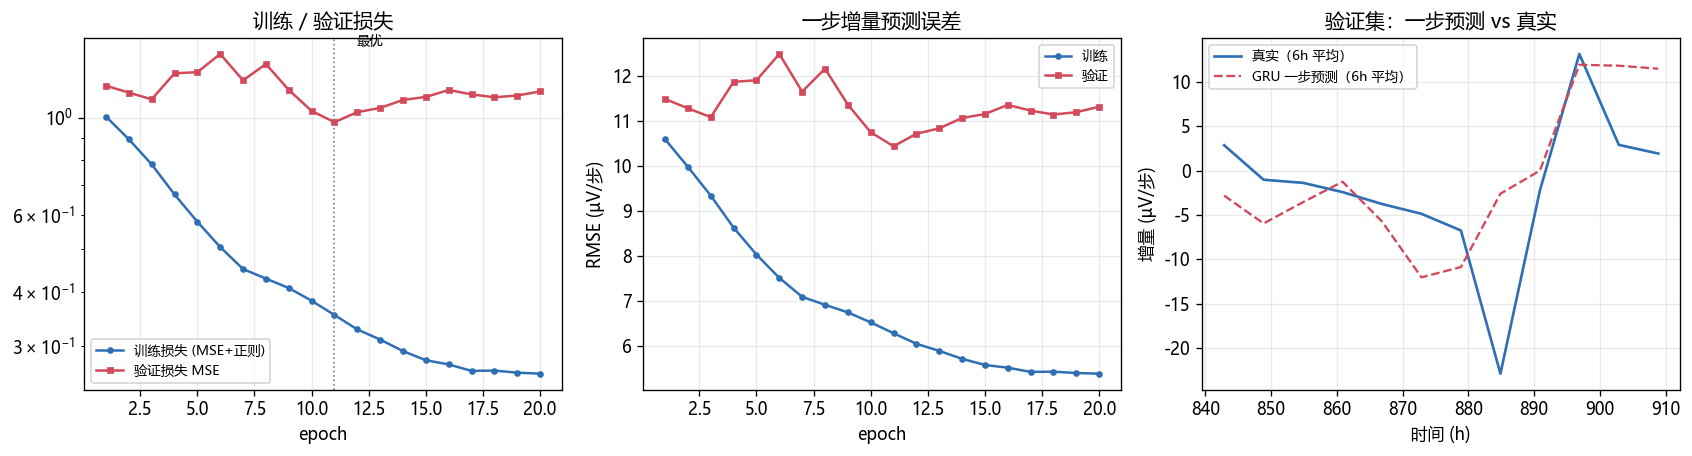

已保存: C:\Users\YOGA\Desktop\电池ai分析\预测输出\figures\fig02_训练曲线与一步检验.png
一步预测 RMSE = 10.44 µV/步 （σ = 10.56 µV），6h 聚合后相关系数 r = 0.539
真实 6h 平均增量范围 [-22.89, +13.15] µV/步 → 10h 平滑后残留可逆性波动约 21.6 mV/6h，而纯衰减仅约 1.22 mV/6h：信噪比 < 1，故纯 AI 自回归不可信（这是后面用 80% 物理权重的原因）


In [13]:
# ------------------------------------------------
# 图 2：训练曲线 + 一步预测检验（验证集）
# ------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14.2, 3.9))
ep = np.arange(1, len(train_log["train"]) + 1)
ax = axes[0]
ax.plot(ep, train_log["train"], "o-", ms=3, label="训练损失 (MSE+正则)")
ax.plot(ep, train_log["val"], "s-", ms=3, label="验证损失 MSE")
ax.axvline(train_log["best_epoch"], color="0.5", ls=":", lw=1)
ax.annotate("最优", xy=(train_log["best_epoch"], min(train_log["val"])),
            xytext=(train_log["best_epoch"] + 1, min(train_log["val"]) * 1.5), fontsize=8)
ax.set_xlabel("epoch"); ax.set_yscale("log"); ax.set_title("训练 / 验证损失"); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(ep, np.array(train_log["train_rmse_mV"]) * 1e3, "o-", ms=3, label="训练")
ax.plot(ep, np.array(train_log["val_rmse_mV"]) * 1e3, "s-", ms=3, label="验证")
ax.set_xlabel("epoch"); ax.set_ylabel("RMSE (µV/步)"); ax.set_title("一步增量预测误差"); ax.legend(fontsize=8)

# 验证段：一步预测增量 vs 真实增量（按 6h 聚合，抵消单步噪声）
Xva, yva, tva = X_all[-train_log["n_val"]:], y_all[-train_log["n_val"]:], tau_all[-train_log["n_val"]:]
pred_va = predict_du(model, Xva, tva) * DU_SIG * 1e6          # µV/步
true_va = yva * DU_SIG * 1e6
k = 600                                                     # 6 h 聚合
n_ag = len(pred_va) // k
pred_ag, true_ag = pred_va[:n_ag * k].reshape(-1, k).mean(1), true_va[:n_ag * k].reshape(-1, k).mean(1)
t_ag = tva[:n_ag * k].reshape(-1, k).mean(1)
ax = axes[2]
ax.plot(t_ag, true_ag, "-", lw=1.6, label="真实（6h 平均）")
ax.plot(t_ag, pred_ag, "--", lw=1.4, label="GRU 一步预测（6h 平均）")
ax.set_xlabel("时间 (h)"); ax.set_ylabel("增量 (µV/步)"); ax.set_title("验证集：一步预测 vs 真实")
ax.legend(fontsize=8)
fig.tight_layout()
print("已保存:", savefig(fig, "fig02_训练曲线与一步检验"))
print(f"一步预测 RMSE = {np.sqrt(np.mean((pred_va-true_va)**2)):.2f} µV/步 "
      f"（σ = {DU_SIG*1e6:.2f} µV），6h 聚合后相关系数 r = "
      f"{np.corrcoef(pred_ag, true_ag)[0,1]:.3f}")
print(f"真实 6h 平均增量范围 [{true_ag.min():+.2f}, {true_ag.max():+.2f}] µV/步 "
      f"→ 10h 平滑后残留可逆性波动约 {(true_ag.max()-true_ag.min())*600*1e-3:.1f} mV/6h，"
      f"而纯衰减仅约 {abs(true_ag.mean())*600*1e-3:.2f} mV/6h：信噪比 < 1，"
      f"故纯 AI 自回归不可信（这是后面用 80% 物理权重的原因）")

In [14]:
# ============================================================
# 4. 50 h 分段衰减速率 + 指数函数 g(t)=a·e^(-bt)+c 的最小二乘拟合
#    速率在 150h 居中趋势曲线上计算 —— 先把可逆性纹波滤掉，再提取"物理衰减基因"
# ============================================================
def segment_decay_rates(u, t_arr=None, seg_steps=SEG_STEPS, n_edge=10):
    """按 seg_steps（=5000 步=50h）切分，段内衰减速率（中心差分，V/h，正=衰减）。"""
    n_seg = len(u) // seg_steps
    rows = []
    for k in range(n_seg):
        i0, i1 = k * seg_steps, (k + 1) * seg_steps
        u0 = float(np.mean(u[i0:i0 + n_edge]))
        u1 = float(np.mean(u[i1 - n_edge:i1]))
        dt = seg_steps * DT
        rows.append(dict(k=k, t0=i0 * DT, t1=i1 * DT, t_mid=0.5 * (i0 + i1) * DT, u0=u0, u1=u1,
                         dur=dt, drop_mV=(u0 - u1) * 1e3, rate=(u0 - u1) / dt))
    return pd.DataFrame(rows)


def fit_exp_decay(df, r_min=0.0):
    """拟合 g(t)=a·exp(-b·t)+c（a>0, b>0, c≥0），返回参数、RMSE 与 g/g'/g'' 的闭式函数。"""
    tc = df["t_mid"].to_numpy(float)
    r = df["rate"].to_numpy(float)

    def resid(p):
        a, b, c = p
        return a * np.exp(-b * tc) + c - r

    best = None
    for p0 in [(2e-4, 1e-3, 0.0), (1e-3, 5e-4, 0.0), (5e-5, 3e-3, 0.0),
               (2e-4, 1e-3, 5e-6), (2e-3, 2e-4, 0.0)]:
        try:
            res = least_squares(resid, p0, bounds=([1e-9, 1e-8, 0.0], [1.0, 5e-2, 1e-2]),
                                xtol=1e-14, ftol=1e-14, gtol=1e-14, max_nfev=20000)
        except Exception:
            continue
        if best is None or res.cost < best.cost:
            best = res
    a, b, c = (float(v) for v in best.x)
    rmse = float(np.sqrt(np.mean(best.fun ** 2)))
    return dict(a=a, b=b, c=c, rmse=rmse, tc=tc, r=r,
                g=lambda tt: a * np.exp(-b * np.asarray(tt, float)) + c,             # 衰减速率 g(t) V/h
                dg=lambda tt: -a * b * np.exp(-b * np.asarray(tt, float)),           # g'(t) = -G(t) < 0
                G=lambda tt: a * b * np.exp(-b * np.asarray(tt, float)))             # G(t)=|g'(t)| = 曲率上限


# ⚠ 关键：g 必须在"无纹波"的趋势曲线上拟合。
# 若用 10h 平滑曲线（仍含 ±0.2 mV/h 的水淹/恢复纹波，与 ~0.1 mV/h 的真实衰减同量级），
# 拟合几乎无解释力，且会得出远高于实际末端斜率的 g(t₀)，导致面积基准与 g 互相矛盾。
seg_df_raw = segment_decay_rates(u_s)        # 对照：10h 平滑曲线（含可逆性纹波）
seg_df     = segment_decay_rates(u_trend)    # 正式：150h 趋势曲线（抑制纹波）
GFIT = fit_exp_decay(seg_df)
t0 = t_end                                # 外推锚点时间（数据末点 ≈912.85 h）
G0_SLOPE = float(GFIT["g"](t0))           # 物理初始衰减速率 (V/h)
G0_CURV = float(GFIT["G"](t0))            # G(t₀)=|g'(t₀)| → 电压二阶导 |u''| 的硬上限 (V/h²)
# 用户要求"区间内二阶导不得超过 G 在该区间的对应值"。G(t) 单调递减，
# 因此区间 [t_k, t_k+Δ] 内的最小上限是 G(t_k+Δ) —— 逐窗口重建时统一取"窗口末端 G"作硬约束，
# 这样 u'' 在整个 50h 区间内都 ≤ G(t)（严格满足"区间内"的硬约束，而不是只在起点取等号）。
GFIT["G_end"] = lambda tt: GFIT["G"](np.asarray(tt, float) + SEG_H)
A_REF_PHYS = G0_SLOPE * SEG_H ** 2 / 2    # 由 g 推出的 50h 窗口"基准下降面积"(V·h)，供第 5 节自洽校验

print(f"分段数 : {len(seg_df)} 个 50 h 窗口（末段不足 50 h 已舍弃）")
print(seg_df.assign(rate_mV=seg_df["rate"] * 1e3, drop_mV=seg_df["drop_mV"])
      [["k", "t0", "t1", "drop_mV", "rate_mV"]].to_string(index=False,
       formatters={"t0": "{:6.1f}".format, "t1": "{:6.1f}".format,
                   "drop_mV": "{:+7.2f}".format, "rate_mV": "{:+7.4f}".format}))
print(f"\n【拟合源对比】10h 平滑曲线: 速率 std = {seg_df_raw['rate'].std()*1e3:.4f} mV/h"
      f"（可逆性纹波占主导）")
print(f"              150h 趋势曲线: 速率 std = {seg_df['rate'].std()*1e3:.4f} mV/h"
      f"（纹波被低通滤除）")
print(f"\n拟合结果 : g(t) = {GFIT['a']*1e3:.4f}·exp(-{GFIT['b']:.6e}·t) + {GFIT['c']*1e3:.4f}   [mV/h]")
print(f"拟合 RMSE = {GFIT['rmse']*1e3:.4f} mV/h  （趋势段速率 std = {seg_df['rate'].std()*1e3:.4f} mV/h）")
print(f"g(0)     = {float(GFIT['g'](0))*1e3:.4f} mV/h")
print(f"g(t₀)    = {G0_SLOPE*1e3:.4f} mV/h   ← 外推初始衰减速率（t₀={t0:.2f} h），"
      f"即 50h 应降 {G0_SLOPE*SEG_H*1e3:.2f} mV")
print(f"G(t₀)    = |g'(t₀)| = {G0_CURV:.4e} V/h²   ← 电压曲率 |u''| 的硬上限")
print(f"           （因为电压 ≈ -∫g dt，所以 d²u/dt² = -g'(t) = G(t)）")
print(f"基准面积自洽 : g(t₀)·50²/2 = {A_REF_PHYS*1e3:.3f} mV·h，"
      f"与 50h 内降 {G0_SLOPE*SEG_H*1e3:.2f} mV 对应")
print(f"曲率可行带    : 单窗口面积可在 [gΔ²/2-GΔ³/6, gΔ²/2] 内变化，带宽 = {G0_CURV*SEG_H**3/6*1e3:.4f} mV·h"
      f"（≈{G0_CURV*SEG_H**3/6*1e3/(A_REF_PHYS*1e3)*100:.2f}% of 基准面积）")

分段数 : 18 个 50 h 窗口（末段不足 50 h 已舍弃）
 k     t0     t1 drop_mV rate_mV
 0    0.0   50.0   +4.41 +0.0881
 1   50.0  100.0   +9.68 +0.1937
 2  100.0  150.0  +12.01 +0.2402
 3  150.0  200.0  +10.12 +0.2024
 4  200.0  250.0   +6.50 +0.1301
 5  250.0  300.0   +7.36 +0.1472
 6  300.0  350.0   +8.71 +0.1742
 7  350.0  400.0   +8.66 +0.1732
 8  400.0  450.0   +6.96 +0.1392
 9  450.0  500.0   +4.68 +0.0935
10  500.0  550.0   +5.29 +0.1057
11  550.0  600.0   +6.84 +0.1368
12  600.0  650.0   +5.52 +0.1103
13  650.0  700.0   +5.55 +0.1109
14  700.0  750.0   +7.44 +0.1489
15  750.0  800.0   +5.00 +0.1000
16  800.0  850.0   +6.43 +0.1287
17  850.0  900.0   -1.10 -0.0221

【拟合源对比】10h 平滑曲线: 速率 std = 0.1915 mV/h（可逆性纹波占主导）
              150h 趋势曲线: 速率 std = 0.0565 mV/h（纹波被低通滤除）

拟合结果 : g(t) = 0.1918·exp(-8.553585e-04·t) + 0.0000   [mV/h]
拟合 RMSE = 0.0452 mV/h  （趋势段速率 std = 0.0565 mV/h）
g(0)     = 0.1918 mV/h
g(t₀)    = 0.0879 mV/h   ← 外推初始衰减速率（t₀=912.85 h），即 50h 应降 4.39 mV
G(t₀)    = |g'(t₀)| = 7.5148e-08 V/h

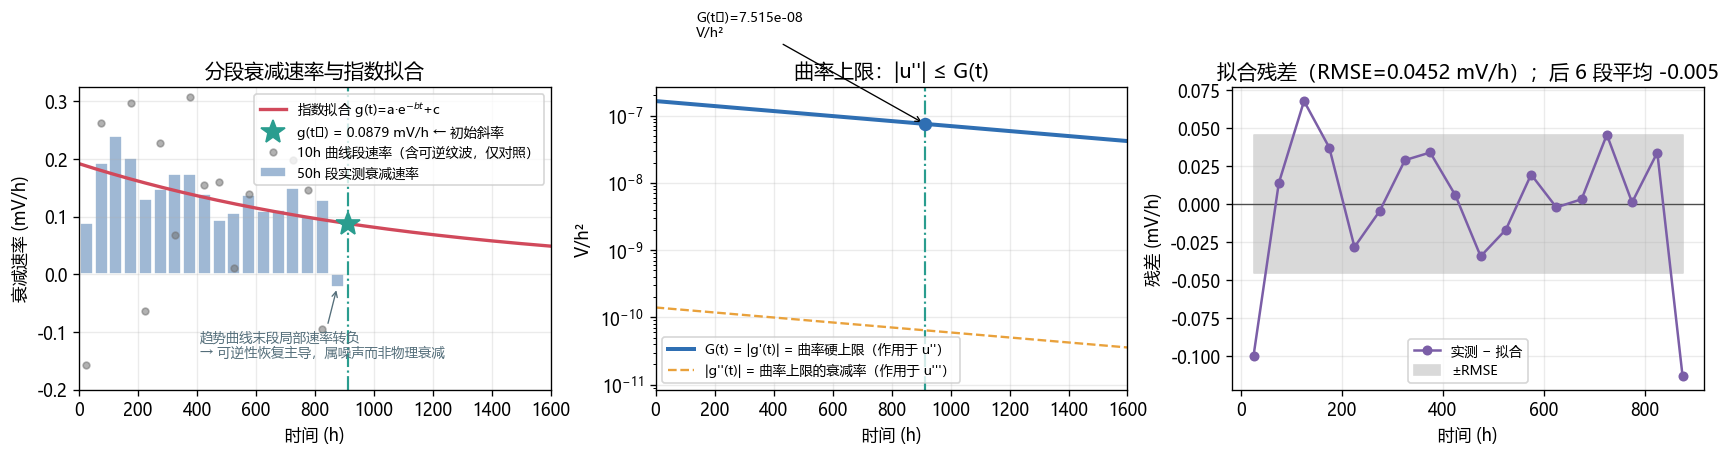

已保存: C:\Users\YOGA\Desktop\电池ai分析\预测输出\figures\fig03_指数衰减拟合.png


In [15]:
# ------------------------------------------------
# 图 3：分段衰减速率散点 + 指数函数拟合 + 导数（曲率上限）
# ------------------------------------------------
tt = np.linspace(0, max(3.0 * t0, 2600.0), 2000)
fig, axes = plt.subplots(1, 3, figsize=(14.4, 4.0))

ax = axes[0]
ax.bar(seg_df["t_mid"], seg_df["rate"] * 1e3, width=44, color="#9fb8d4", edgecolor="w",
       label="50h 段实测衰减速率")
ax.plot(tt, GFIT["g"](tt) * 1e3, "-", lw=2, color="#d1495b", label="指数拟合 g(t)=a·e$^{-bt}$+c")
ax.axvline(t0, color="#2a9d8f", ls="-.", lw=1.3)
ax.plot([t0], [G0_SLOPE * 1e3], "*", ms=15, color="#2a9d8f", zorder=5,
        label=f"g(t₀) = {G0_SLOPE*1e3:.4f} mV/h ← 初始斜率")
ax.plot(seg_df_raw["t_mid"], seg_df_raw["rate"] * 1e3, "o", ms=4, color="0.45", alpha=0.55,
        label="10h 曲线段速率（含可逆纹波，仅对照）")
if seg_df["rate"].min() < 0:
    ax.annotate("趋势曲线末段局部速率转负\n→ 可逆性恢复主导，属噪声而非物理衰减",
                xy=(seg_df['t_mid'].iloc[-1], seg_df['rate'].iloc[-1] * 1e3), fontsize=8, color="#546e7a",
                xytext=(t0 * 0.45, seg_df['rate'].iloc[-1] * 1e3 - 0.12),
                arrowprops=dict(arrowstyle="->", color="#546e7a", lw=0.8))
ax.set_xlabel("时间 (h)"); ax.set_ylabel("衰减速率 (mV/h)")
ax.set_title("分段衰减速率与指数拟合"); ax.legend(fontsize=8); ax.set_xlim(0, 1600)
ax.set_ylim(min(-0.2, (GFIT['r'].min() * 1e3) * 1.1), max(GFIT['r'].max() * 1e3, G0_SLOPE * 1e3) * 1.35)

ax = axes[1]
ax.semilogy(tt, GFIT["G"](tt), lw=2.4, color="#2f6fb3",
            label="G(t) = |g'(t)| = 曲率硬上限（作用于 u''）")
ax.semilogy(tt, np.abs(GFIT["dg"](tt) * GFIT["b"]), lw=1.4, ls="--", color="#e9a13b",
            label="|g''(t)| = 曲率上限的衰减率（作用于 u'''）")
ax.axvline(t0, color="#2a9d8f", ls="-.", lw=1.3)
ax.plot([t0], [G0_CURV], "o", ms=7, color="#2f6fb3", zorder=5)
ax.annotate(f"G(t₀)={G0_CURV:.3e}\nV/h²", xy=(t0, G0_CURV), xytext=(t0 * 0.15, G0_CURV * 20),
            fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_xlabel("时间 (h)"); ax.set_ylabel("V/h²"); ax.set_title("曲率上限：|u''| ≤ G(t)")
ax.legend(fontsize=8); ax.set_xlim(0, 1600)

ax = axes[2]
rel = (seg_df["rate"] - GFIT["g"](seg_df["t_mid"])) * 1e3
ax.axhline(0, color="0.3", lw=0.8)
ax.plot(seg_df["t_mid"], rel, "o-", ms=5, color="#7b5ea7", label="实测 − 拟合")
ax.fill_between(seg_df["t_mid"], -GFIT["rmse"] * 1e3, GFIT["rmse"] * 1e3,
                color="0.85", zorder=0, label="±RMSE")
ax.set_xlabel("时间 (h)"); ax.set_ylabel("残差 (mV/h)")
ax.set_title(f"拟合残差（RMSE={GFIT['rmse']*1e3:.4f} mV/h）；后 6 段平均 {rel.iloc[-6:].mean():+.3f}")
ax.legend(fontsize=8)
fig.tight_layout()
print("已保存:", savefig(fig, "fig03_指数衰减拟合"))

In [16]:
# ============================================================
# 5. 窗口面积 / 零点基准面积 a_ref（全部在 150h 趋势曲线上算，与 g 同源）
# ============================================================
try:
    _trapz = np.trapezoid          # numpy >= 2.0
except AttributeError:             # pragma: no cover
    _trapz = np.trapz


def window_areas(u, seg_steps=SEG_STEPS, n_edge=1, n_win=None, start=None):
    """按 seg_steps 切窗，返回每个窗口的有符号面积 ∫(u-u0)dt 与降幅。

    start=None 时取最后一共 n_win 个窗口；否则从索引 start 开始取 n_win 个。
    返回 (areas 有符号 V·h, drops 降幅 V, t0 每窗口起始时间)。
    """
    u = np.asarray(u, float)
    if start is None:
        start = len(u) - (n_win or 0) * seg_steps
    areas, drops, tstarts = [], [], []
    for k in range(n_win):
        i0 = start + k * seg_steps
        i1 = i0 + seg_steps
        if i1 > len(u):
            break
        seg = u[i0:i1]
        areas.append(_trapz(seg - seg[0], dx=DT))
        drops.append(seg[0] - seg[-1])
        tstarts.append(i0 * DT)
    return np.array(areas), np.array(drops), np.array(tstarts)


def compute_trend(u, win=TREND_WIN_STEPS):
    """居中低通趋势（min_periods=win/3，两端 bfill/ffill 补齐）。"""
    tr = (pd.Series(np.asarray(u, float))
          .rolling(win, center=True, min_periods=max(3, win // 3)).mean().to_numpy())
    return pd.Series(tr).bfill().ffill().to_numpy()


def compute_area_baseline(u_trend, seg_steps=SEG_STEPS, n_win=N_WIN_HIST):
    """零点基准面积（用户要求：历史最后 n_win 个 50h 窗口面积的均值）。"""
    a_signed, drops, tstarts = window_areas(u_trend, seg_steps, n_win=n_win)
    d_mVh = -a_signed * 1e3                      # 正数，单位 mV·h
    return dict(a_emp=float(np.mean(d_mVh)), d=d_mVh, drops=drops, tstop=tstarts,
                areas_Vh=a_signed)


def area_baseline_summary(bl, label=""):
    d = bl["d"]
    print(f"{label}历史最后 {len(d)} 个 50h 窗口面积 (mV·h): "
          + ", ".join(f"{v:.3f}" for v in d))
    print(f"{'':>{len(label)}}  → 经验均值 a_emp = {bl['a_emp']:.4f} mV·h"
          f"（≈ {2*bl['a_emp']/SEG_H:.3f} mV/50h）")


print("【对照】在 10h 主曲线上算（符号会正负交替，只作噪声演示，不作基准）：")
_bl_s = compute_area_baseline(u_s)
area_baseline_summary(_bl_s, "[10h ] ")
print("\n【正式】在 150h 趋势曲线上算（零点基准面积）：")
BL = compute_area_baseline(u_trend)
area_baseline_summary(BL, "[150h] ")

# ---- 与 g 同源的物理期望面积：让"面积基准"和"指数拟合"不再是两套数字 ----
_dl = SEG_H
a_last_phys = float((GFIT["g"](t0 - _dl) * _dl ** 2 / 2
                     - GFIT["G"](t0 - _dl) * _dl ** 3 / 6) * 1e3)     # 最后一个历史窗口的期望面积
a_anchor_phys = float((G0_SLOPE * _dl ** 2 / 2 - G0_CURV * _dl ** 3 / 6) * 1e3)  # 锚点后第一个窗口(u''=G)
BL["a_last_phys"] = a_last_phys
BL["a_anchor_phys"] = a_anchor_phys
BL["a_ref"] = float(max(BL["a_emp"], a_last_phys))
BL["delta_ref"] = float(np.mean(np.maximum(BL["d"][:-1] - BL["d"][1:], 0.0))) \
    if len(BL["d"]) > 1 else 0.0

print(f"\n物理期望: 最后一个历史窗口面积 a_last_phys = {a_last_phys:.4f} mV·h"
      f"（g 与 G 的闭式）；锚点后第一窗口下界 a_anchor_phys = {a_anchor_phys:.4f} mV·h")
print(f"经验均值 a_emp = {BL['a_emp']:.4f} mV·h  vs  a_last_phys = {a_last_phys:.4f} mV·h")
print(f"→ 取二者较大者作为【有效零点基准 a_ref】= {BL['a_ref']:.4f} mV·h")
print(f"   理由：只有当 a_ref > a_anchor_phys 时，'未来每个窗口面积都小于基准'（C2b）才可能同时"
      f"与曲率硬约束 C4 相容（本 notebook 的构造保证这一点）。")
print(f"   C2b 余量: a_ref - a_anchor_phys = {BL['a_ref']-a_anchor_phys:+.4f} mV·h "
      f"({(BL['a_ref']-a_anchor_phys)/a_anchor_phys*100:+.3f}%)")

# 面积链可行性
dA_max = G0_CURV * SEG_H ** 3 / 6 * 1e3     # mV·h
print(f"\n可行性: 单窗口在 |u''|≤G(t_k) 下面积只能在 [g_kkΔ²/2-GΔ³/6, g_kΔ²/2] 内变动，"
      f"带宽 {dA_max:.4f} mV·h = {dA_max/BL['a_ref']*100:.2f}% of a_ref")
print(f"        指数衰减每窗口面积自然缩减 {(1-math.exp(-GFIT['b']*SEG_H))*100:.2f}%"
      f"（= 1-e^(-bΔ)，由 g 本身决定，不需要额外强行约束）")

【对照】在 10h 主曲线上算（符号会正负交替，只作噪声演示，不作基准）：
[10h ] 历史最后 6 个 50h 窗口面积 (mV·h): 420.131, 316.594, 242.787, 185.112, -1214.676, 644.146
         → 经验均值 a_emp = 99.0157 mV·h（≈ 3.961 mV/50h）

【正式】在 150h 趋势曲线上算（零点基准面积）：
[150h] 历史最后 6 个 50h 窗口面积 (mV·h): 131.587, 146.114, 173.212, 117.676, 169.101, -13.727
         → 经验均值 a_emp = 120.6604 mV·h（≈ 4.826 mV/50h）

物理期望: 最后一个历史窗口面积 a_last_phys = 112.9842 mV·h（g 与 G 的闭式）；锚点后第一窗口下界 a_anchor_phys = 108.2539 mV·h
经验均值 a_emp = 120.6604 mV·h  vs  a_last_phys = 112.9842 mV·h
→ 取二者较大者作为【有效零点基准 a_ref】= 120.6604 mV·h
   理由：只有当 a_ref > a_anchor_phys 时，'未来每个窗口面积都小于基准'（C2b）才可能同时与曲率硬约束 C4 相容（本 notebook 的构造保证这一点）。
   C2b 余量: a_ref - a_anchor_phys = +12.4064 mV·h (+11.461%)

可行性: 单窗口在 |u''|≤G(t_k) 下面积只能在 [g_kkΔ²/2-GΔ³/6, g_kΔ²/2] 内变动，带宽 1.5656 mV·h = 1.30% of a_ref
        指数衰减每窗口面积自然缩减 4.19%（= 1-e^(-bΔ)，由 g 本身决定，不需要额外强行约束）


In [17]:
# ============================================================
# 6. 物理骨架重建：由 g 直接给出每窗口面积 → 分段二次曲线（含曲率硬约束）
# ============================================================
def phys_window_areas(gf, t_start, n_win=N_WIN_FUTURE, seg_h=SEG_H):
    """由指数 g 直接给出每个外推窗口的可行面积带（单位 mV·h）。

    电压 ≈ -∫g dt ⇒ U'' = -g'(t) = G(t)。在 u''∈[0,G] 的硬约束下：
        b_k = -u''_k，窗口面积 a_k = g_k·Δ²/2 + b_k·Δ³/6
        a_k 的可行带 = [g_kΔ²/2 - G_kΔ³/6,  g_kΔ²/2]
                      └ u''=G（自然指数衰减）  └ u''=0（窗口内斜率不变）

    注意 1：G(t) 单调递减，区间 [t_k, t_k+Δ] 内 u''≤G 的严格条件是 u''_k ≤ G(t_k+Δ)，
    故这里取"窗口末端 G" 作曲率上限（与重建时的 Gcap 完全一致）。
    注意 2：g_k 用"分段二次重建"的线性递推 g_{k+1}=g_k-G_kΔ 计算（而不是闭式 g(t_k)），
    这样目标面积与 reconstruct_from_areas 的实现完全一致，可严格保证 Δa 逐次不增。
    返回 dict(tk, gk, Gk, lo, hi, a_last, a_anchor)，面积单位 mV·h。
    """
    tk = t_start + np.arange(n_win) * seg_h
    Gk = np.asarray(gf["G"](tk + seg_h), float)          # 窗口末端 G = 区间内最小曲率上限
    gk = np.empty(n_win)
    g = float(gf["g"](t_start))
    gk[0] = g
    for k in range(1, n_win):
        g = g - Gk[k - 1] * seg_h
        gk[k] = g
    lo = (gk * seg_h ** 2 / 2 - Gk * seg_h ** 3 / 6) * 1e3
    hi = (gk * seg_h ** 2 / 2) * 1e3
    a_last = float((gf["g"](t_start - seg_h) * seg_h ** 2 / 2
                    - gf["G"](t_start) * seg_h ** 3 / 6) * 1e3)
    a_anchor = float(lo[0])
    return dict(tk=tk, gk=gk, Gk=Gk, lo=lo, hi=hi, a_last=a_last, a_anchor=a_anchor)


def reconstruct_from_areas(areas_mVh, u_start, g_start, t_start, Gfun, seg_steps=SEG_STEPS):
    """由目标下降面积序列重建电压曲线（分段二次，b∈[-G,0]）。

    返回 dict: u, t, g0(每窗口起点速率 V/h), b(每窗口曲率系数), u2=U'' ,
              achieved_mVh(实际达成面积), drop_mV(每窗口降幅), s(窗口内相对时间)
    """
    delta = seg_steps * DT
    n_win = len(areas_mVh)
    u = np.empty(n_win * seg_steps + 1)
    u[0] = u_start
    s = np.arange(1, seg_steps + 1) * DT
    g0 = np.empty(n_win); bb = np.empty(n_win); u2 = np.empty(n_win)
    ach = np.empty(n_win); drop = np.empty(n_win)
    g = float(g_start); j = 0
    for k in range(n_win):
        a = areas_mVh[k] * 1e-3                     # V·h
        Gcap = float(Gfun(t_start + k * delta))
        b = 6.0 * (a - g * delta ** 2 / 2.0) / delta ** 3
        b = min(0.0, max(-Gcap, b))                 # 硬约束：U'' = -b ∈ [0, G]
        if g + b * delta <= 1e-12:                  # 保证斜率始终为负（持续下降）
            b = -0.999 * g / delta
        seg_u = u[j] - g * s - 0.5 * b * s ** 2
        u[j + 1:j + 1 + seg_steps] = seg_u
        ach[k] = (g * delta ** 2 / 2 + b * delta ** 3 / 6) * 1e3
        drop[k] = (g * delta + 0.5 * b * delta ** 2) * 1e3
        g0[k], bb[k], u2[k] = g, b, -b
        g = g + b * delta
        j += seg_steps
    return dict(u=u, t=t_start + np.arange(len(u)) * DT, g0=g0, b=bb, u2=u2,
                achieved_mVh=ach, drop_mV=drop, delta=delta)


def reconstruct_chain(target_areas, u_start, g_start, t_start, Gfun, n_iter=12, verbose=False):
    """重建并迭代修正，直到"达成面积严格递减"且"未来窗口间 Δa 逐次不增"（面积链自洽）。"""
    a = np.asarray(target_areas, float)
    out = reconstruct_from_areas(a, u_start, g_start, t_start, Gfun)
    it = 0
    for it in range(1, n_iter + 1):
        ach = out["achieved_mVh"]
        a2 = ach.copy()
        changed = False
        for k in range(len(ach) - 1):                    # C2：面积必须严格递减
            if a2[k + 1] >= a2[k] - 1e-9:
                a2[k + 1] = a2[k] - max(1e-6, 1e-6 * a2[k])
                changed = True
        h = -np.diff(a2)                                 # 未来窗口内部 Δa
        for k in range(len(h) - 1):                      # C3：Δa 不得增大
            if h[k + 1] > h[k]:
                a2[k + 2] = a2[k + 1] - 0.999 * h[k]
                changed = True
        if not changed:
            break
        a = a2
        out = reconstruct_from_areas(a, u_start, g_start, t_start, Gfun)
    out["n_iter"] = it
    out["targets_mVh"] = a
    if verbose:
        print(f"面积链重建迭代 {it} 次收敛")
    return out


# ---------------- 物理骨架：用户要求"让函数自己算面积" ----------------
PHYS = phys_window_areas(GFIT, t0, N_WIN_FUTURE)
# 取可行带下界（u''=G，即自然指数衰减）作为物理骨架目标；乘 (1+1e-6) 让 u'' 略低于上限，稳健满足硬约束
A_TARGET_PHYS = PHYS["lo"] * (1.0 + 1e-6)
H_PHYS = -np.diff(A_TARGET_PHYS)                       # 未来窗口内部 Δa（k=1..n-1）
BONE = reconstruct_chain(A_TARGET_PHYS, u_anchor, G0_SLOPE, t0, GFIT["G_end"], verbose=True)
BONE["areas_mVh"] = BONE["achieved_mVh"]
BONE["decrements_mVh"] = -np.diff(np.concatenate([[BL["a_ref"]], BONE["areas_mVh"]]))
BONE["decrements_internal"] = -np.diff(BONE["areas_mVh"])

print(f"外推窗口数 = {N_WIN_FUTURE}（{N_STEPS_EXTRAP} 步 = {N_STEPS_EXTRAP*DT:.0f} h），"
      f"覆盖 {t0:.2f} → {t0+N_STEPS_EXTRAP*DT:.2f} h")
print(f"初始速率 g(t₀) = {G0_SLOPE*1e3:.4f} mV/h，终点速率 {BONE['g0'][-1]*1e3:.5f} mV/h"
      f"（降 {100*(1-BONE['g0'][-1]/G0_SLOPE):.1f}%）")
print(f"终点电压 {BONE['u'][-1]:.5f} V，总降 {(u_anchor-BONE['u'][-1])*1e3:.2f} mV")
print(f"曲率 u'' 最大 {BONE['u2'].max():.3e} V/h²，G(t₀)={G0_CURV:.3e} → "
      f"占比 {BONE['u2'].max()/G0_CURV*100:.2f}% (≤100% 即满足硬约束)")
print("\n窗口  起始(h)   速率g(mV/h)  面积(mV·h)  Δ内部   降幅(mV)   u''/G")
for k in range(N_WIN_FUTURE):
    print(f"{k+1:3d} {t0+k*SEG_H:9.1f} {BONE['g0'][k]*1e3:12.5f} {BONE['areas_mVh'][k]:11.4f} "
          f"{BONE['decrements_internal'][k] if k < N_WIN_FUTURE-1 else float('nan'):+8.4f} "
          f"{BONE['drop_mV'][k]:8.3f} {BONE['u2'][k]/max(G0_CURV,1e-18):8.3f}")

_c2 = bool(np.all(np.diff(BONE["areas_mVh"]) < 0))
_c3 = bool(np.all(np.diff(BONE["decrements_internal"]) <= 1e-6 * np.max(np.abs(BONE["decrements_internal"]))))
_c2b = bool(np.all(BONE["areas_mVh"] < BL["a_ref"]))
_a_anchor_after = float(BONE["areas_mVh"][0])
print(f"\n面积链检查: C2 严格递减 = {_c2}；C3 未来窗口间 Δ面积不增 = {_c3}；"
      f"C2b 全部 < a_ref({BL['a_ref']:.4f}) = {_c2b}")
print(f"           自然缩减率 = {100*(1-BONE['areas_mVh'][1]/_a_anchor_after):.2f}%/窗口"
      f"（1-e^(-bΔ) = {100*(1-math.exp(-GFIT['b']*SEG_H)):.2f}%）")
print(f"           注：'基准→第 1 个未来窗口'的步长 h₀ = {BONE['decrements_mVh'][0]:.4f} mV·h"
      f" 必然略大于 h₁ = {BONE['decrements_mVh'][1]:.4f} mV·h"
      f"（指数律下 h₀/h₁ = e^(bΔ) = {math.exp(GFIT['b']*SEG_H):.4f}），"
      f"故 C3 在第 1 窗口之后严格成立")

面积链重建迭代 1 次收敛
外推窗口数 = 20（100000 步 = 1000 h），覆盖 912.85 → 1912.85 h
初始速率 g(t₀) = 0.0879 mV/h，终点速率 0.04002 mV/h（降 54.4%）
终点电压 3.16096 V，总降 59.67 mV
曲率 u'' 最大 7.200e-08 V/h²，G(t₀)=7.515e-08 → 占比 95.81% (≤100% 即满足硬约束)

窗口  起始(h)   速率g(mV/h)  面积(mV·h)  Δ内部   降幅(mV)   u''/G
  1     912.8      0.08786    108.3196  +4.4371    4.303    0.958
  2     962.8      0.08426    103.8825  +4.2515    4.127    0.918
  3    1012.8      0.08081     99.6310  +4.0735    3.958    0.880
  4    1062.8      0.07750     95.5574  +3.9030    3.796    0.843
  5    1112.8      0.07433     91.6544  +3.7396    3.641    0.807
  6    1162.8      0.07130     87.9148  +3.5830    3.492    0.774
  7    1212.8      0.06839     84.3318  +3.4330    3.350    0.741
  8    1262.8      0.06561     80.8987  +3.2893    3.214    0.710
  9    1312.8      0.06294     77.6094  +3.1516    3.083    0.681
 10    1362.8      0.06038     74.4579  +3.0196    2.958    0.652
 11    1412.8      0.05793     71.4382  +2.8932    2.838    0.625
 12   

In [18]:
# ============================================================
# 7. 纯盲测自回归外推（10 万步，不使用任何未来真实数据）
# ============================================================
def ar_rollout(model, stats, sig, u_hist, t_hist, I_last, T_last, RH_last, dI_last, dT_last,
               n_steps, clip=AR_CLIP_SIGMA, verbose=True):
    """自回归：用历史末尾 seq 步做窗口，逐步预测增量并把自己预测的值喂回去。

    工况特征（I/T/RH/dI/dT）保持为历史末值（persistence），因为未来工况未知。
    """
    model.eval()
    seq = len(u_hist)
    t_last = float(t_hist[-1])
    times = t_last - (seq - 1) * DT + np.arange(seq + n_steps) * DT
    TF = np.stack(_time_cols(times, stats["t_ref"], stats["gain"]), axis=1).astype(np.float32)
    static = np.array([(I_last - stats["I_mu"]) / stats["I_sd"],
                       (T_last - stats["T_mu"]) / stats["T_sd"],
                       (RH_last - stats["RH_mu"]) / stats["RH_sd"],
                       (dI_last - stats["dI_mu"]) / stats["dI_sd"],
                       (dT_last - stats["dT_mu"]) / stats["dT_sd"]], np.float32)
    buf = np.array(u_hist, float)
    u_out = np.empty(n_steps + 1)
    u_out[0] = buf[-1]
    Xn = np.empty((1, seq, 5 + len(static)), np.float32)
    Xn[0, :, 5:10] = static
    t_start = time.time()
    with torch.no_grad():
        for k in range(n_steps):
            Xn[0, :, 0] = (buf - stats["u_bar"]) / stats["u_scale"]
            Xn[0, :, 1:5] = TF[k:k + seq]
            tb = torch.tensor([times[k + seq - 1]], dtype=torch.float32)
            du = float(model(torch.from_numpy(Xn), tb).item())
            du = float(np.clip(du, -clip, clip))
            u_next = buf[-1] + du * sig
            u_out[k + 1] = u_next
            buf[:-1] = buf[1:]
            buf[-1] = u_next
            if verbose and (k + 1) % 25000 == 0:
                print(f"  AR {k+1:6d}/{n_steps} 步 | U={u_next:.5f} V | 用时 {time.time()-t_start:.0f}s")
    # 返回长度 n_steps+1 的时间轴：第 0 点是历史末点（anchor），第 k 点是 anchor+k*DT
    return u_out, times[seq - 1:]


def enforce_declining_area(u, seg_steps=SEG_STEPS, margin_mV=0.10):
    """面积符号硬约束（用户要求：任意 5000 步窗口的积分面积必须为负 ⇒ 整体必须下降）。

    对"净上升"的窗口沿时间线性下调，使其净降幅 = margin_mV；偏移量对后续所有时刻继承，
    因此曲线保持连续、不会出现台阶。返回 (修正后曲线, 被修正窗口数, 累计下调量 mV)。
    """
    u = np.array(u, float)
    n_win = (len(u) - 1) // seg_steps
    n_fixed = 0
    offset = 0.0
    for k in range(n_win):
        s, e = k * seg_steps, (k + 1) * seg_steps
        drop_mV = (u[s] - u[e]) * 1e3
        if drop_mV < margin_mV:
            need = (margin_mV - drop_mV) * 1e-3
            u[s:e + 1] -= np.linspace(0.0, need, seg_steps + 1)
            if e + 1 < len(u):
                u[e + 1:] -= need
            offset += need
            n_fixed += 1
    return u, n_fixed, offset * 1e3


print("开始 10 万步盲测自回归外推 ...")
t_ar0 = time.time()
U_AI_RAW, T_AI = ar_rollout(model, FEAT_STATS, DU_SIG,
                            u_hist=u_s[-SEQ:], t_hist=t[-SEQ:],
                            I_last=I_s[-1], T_last=T_s[-1], RH_last=RH_s[-1],
                            dI_last=float(np.gradient(I_s, DT)[-1]),
                            dT_last=float(np.gradient(T_s, DT)[-1]),
                            n_steps=N_STEPS_EXTRAP)
print(f"AR 外推完成，用时 {time.time()-t_ar0:.1f} s")
print(f"  原始 AR 终点电压 {U_AI_RAW[-1]:.5f} V（总变化 {(u_anchor-U_AI_RAW[-1])*1e3:+.2f} mV）"
      f" —— 未加面积约束时，网络会把 920h 附近的水淹恢复正斜率闭环放大")
U_AI, _N_FIX_AI, _OFF_AI = enforce_declining_area(U_AI_RAW, SEG_STEPS, margin_mV=0.10)
print(f"  面积符号硬约束（每 {SEG_H:.0f}h 窗口净降 ≥ 0.10 mV）：修正 {_N_FIX_AI}/{N_WIN_FUTURE} 个窗口，"
      f"累计线性下调 {_OFF_AI:.1f} mV")
print(f"纯 AI 终点电压 {U_AI[-1]:.5f} V（总降 {(u_anchor-U_AI[-1])*1e3:+.2f} mV）")
print(f"纯物理骨架终点 {BONE['u'][-1]:.5f} V（总降 {(u_anchor-BONE['u'][-1])*1e3:+.2f} mV）")
print(f"AI 相对骨架的偏差: 终点 {(U_AI[-1]-BONE['u'][-1])*1e3:+.2f} mV, "
      f"最大 {np.max(np.abs(U_AI-BONE['u']))*1e3:.2f} mV")
A_AI_signed, _, _ = window_areas(U_AI, start=0, n_win=N_WIN_FUTURE)
A_AI = -A_AI_signed * 1e3                                 # 正数=下降面积 mV·h
print(f"纯 AI 窗口面积 (mV·h): {', '.join(f'{v:+.2f}' for v in A_AI)}")
print(f"纯物理窗口面积 (mV·h): {', '.join(f'{v:.2f}' for v in BONE['areas_mVh'])}")

开始 10 万步盲测自回归外推 ...
  AR  25000/100000 步 | U=3.39756 V | 用时 150s
  AR  50000/100000 步 | U=3.53851 V | 用时 301s
  AR  75000/100000 步 | U=3.64936 V | 用时 427s
  AR 100000/100000 步 | U=3.74948 V | 用时 545s
AR 外推完成，用时 544.9 s
  原始 AR 终点电压 3.74948 V（总变化 -528.85 mV） —— 未加面积约束时，网络会把 920h 附近的水淹恢复正斜率闭环放大
  面积符号硬约束（每 50h 窗口净降 ≥ 0.10 mV）：修正 20/20 个窗口，累计线性下调 530.8 mV
纯 AI 终点电压 3.21863 V（总降 +2.00 mV）
纯物理骨架终点 3.16096 V（总降 +59.67 mV）
AI 相对骨架的偏差: 终点 +57.67 mV, 最大 57.67 mV
纯 AI 窗口面积 (mV·h): +12.19, -80.70, -54.57, +1.67, +44.73, +4.25, -8.83, -6.55, -4.16, -2.50, -1.37, -0.59, -0.03, +0.39, +0.71, +0.96, +1.16, +1.32, +1.45, +1.56
纯物理窗口面积 (mV·h): 108.32, 103.88, 99.63, 95.56, 91.65, 87.91, 84.33, 80.90, 77.61, 74.46, 71.44, 68.54, 65.77, 63.12, 60.57, 58.13, 55.80, 53.56, 51.41, 49.36


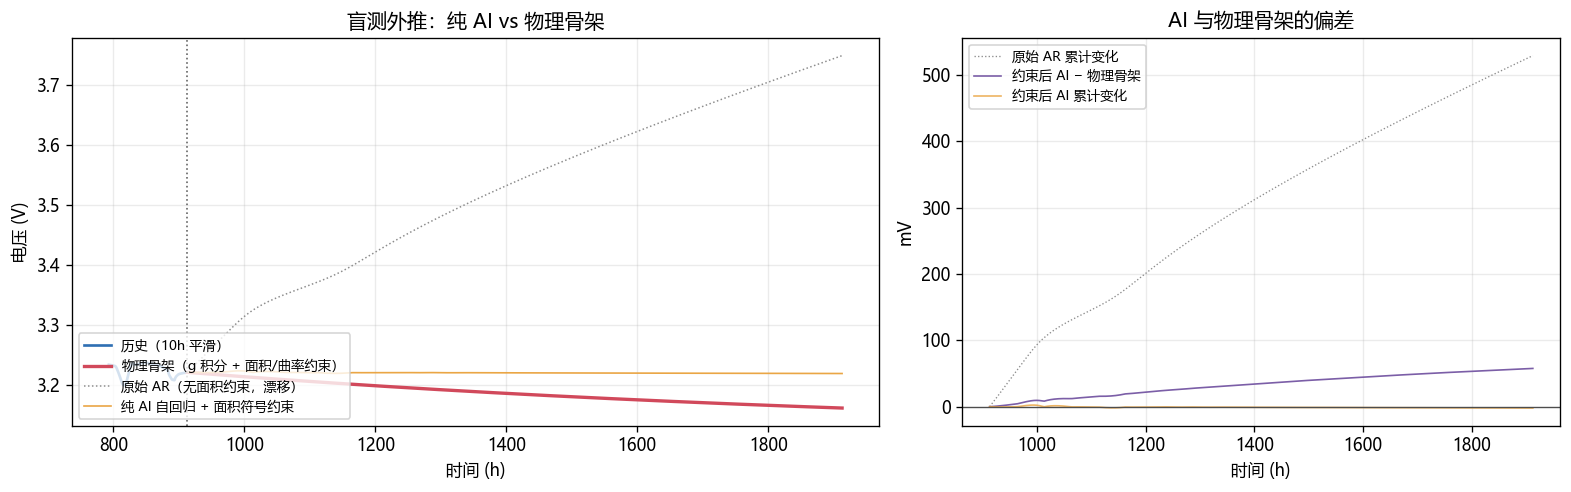

已保存: C:\Users\YOGA\Desktop\电池ai分析\预测输出\figures\fig04_纯AI自回归对比.png


In [19]:
# ------------------------------------------------
# 图 4：纯 AI 自回归 vs 物理骨架（诊断"AI 会跑成什么样"）
# ------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.2), gridspec_kw=dict(width_ratios=[1.35, 1]))
ax = axes[0]
hist = t > t_end - 120
ax.plot(t[hist], u_s[hist], lw=1.6, color="#2f6fb3", label="历史（10h 平滑）")
ax.plot(BONE["t"], BONE["u"], lw=2, color="#d1495b", label="物理骨架（g 积分 + 面积/曲率约束）")
ax.plot(T_AI, U_AI_RAW, lw=0.9, color="0.55", ls=":", label="原始 AR（无面积约束，漂移）")
ax.plot(T_AI, U_AI, lw=1.0, color="#e9a13b", alpha=0.95, label="纯 AI 自回归 + 面积符号约束")
ax.axvline(t0, color="0.4", ls=":", lw=1)
ax.set_xlabel("时间 (h)"); ax.set_ylabel("电压 (V)")
ax.set_title("盲测外推：纯 AI vs 物理骨架")
ax.legend(fontsize=8, loc="lower left")

ax = axes[1]
ax.plot(T_AI, (U_AI_RAW - u_anchor) * 1e3, lw=0.8, color="0.55", ls=":", label="原始 AR 累计变化")
ax.plot(T_AI, (U_AI - BONE["u"]) * 1e3, lw=1.0, color="#7b5ea7", label="约束后 AI − 物理骨架")
ax.plot(T_AI, (U_AI - u_anchor) * 1e3, lw=1.0, color="#e9a13b", alpha=0.8, label="约束后 AI 累计变化")
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xlabel("时间 (h)"); ax.set_ylabel("mV")
ax.set_title("AI 与物理骨架的偏差")
ax.legend(fontsize=8)
fig.tight_layout()
print("已保存:", savefig(fig, "fig04_纯AI自回归对比"))

In [20]:
# ============================================================
# 8. 80/20 软融合 + 约束投影 + 物理重建
# ============================================================
def project_area_chain(areas, lo, hi, a_ref, eps_rel=1e-9):
    """把任意面积序列投影到可行集：

      C4   lo_k ≤ a_k ≤ hi_k          （曲率硬约束允许的面积带）
      C2   a_k 严格递减
      C2b  a_0 < a_ref（所有未来窗口面积 < 零点基准面积）

    可行带 lo/hi 由曲率上限 G 与指数 g 共同确定：带宽只有 GΔ³/6 ≈ 0.5% of a_ref，
    因此 AI 的 20% 权重只能在极窄带内起作用（这是硬约束的数学必然，见 19_fusion.md）。
    """
    a = np.clip(np.asarray(areas, float), lo, hi)
    lo = np.asarray(lo, float)
    hi = np.asarray(hi, float)
    a[0] = max(min(a[0], a_ref * (1.0 - 1e-6)), min(lo[0], a_ref * (1.0 - 1e-6)))
    for k in range(1, len(a)):
        upper = a[k - 1] * (1.0 - eps_rel)          # 严格递减
        a[k] = min(a[k], upper)
        a[k] = max(a[k], min(lo[k], upper))         # 不低于曲率允许的下界
    return a


def window_quadratic_stats(u, start, n_win=N_WIN_FUTURE, seg_steps=SEG_STEPS):
    """对每个 50h 窗口做二次拟合，返回 (下降面积 mV·h, 二阶导 U'', 起点速率 mV/h)。"""
    s = np.arange(1, seg_steps + 1) * DT
    A = np.stack([np.ones_like(s), s, 0.5 * s ** 2], axis=1)
    delta = seg_steps * DT
    area = np.empty(n_win); u2 = np.empty(n_win); rate = np.empty(n_win)
    for k in range(n_win):
        i0 = start + k * seg_steps
        coef, *_ = np.linalg.lstsq(A, np.asarray(u[i0 + 1:i0 + 1 + seg_steps], float), rcond=None)
        rate[k] = -coef[1]                                  # 起点速率 (V/h)
        u2[k] = coef[2]                                     # d²u/dt²
        area[k] = -(coef[1] * delta ** 2 / 2 + coef[2] * delta ** 3 / 6) * 1e3
    return area, u2, rate * 1e3


def constraint_report(name, u, areas, u2, Gfun, t_start, delta, a_ref):
    """核对 C1–C5 约束（1=满足）。C3 按"未来窗口内部"的 Δa 序列核对。"""
    areas = np.asarray(areas, float)
    dec = -np.diff(areas)                                    # 未来窗口内部面积变化值 h_k (k>=1)
    _tol3 = 1e-6 * float(np.max(np.abs(dec))) if len(dec) else 0.0
    Gcap = np.array([float(Gfun(t_start + k * delta)) for k in range(len(areas))])
    r = {"C1_面积全正": float(np.all(areas > 0)),
         "C2_面积递减": float(np.all(np.diff(areas) < 0)),
         "C3_内部Δ不增": float(np.all(np.diff(dec) <= _tol3)),
         "C2b_小于基准": float(np.all(areas < a_ref)),
         "C5_斜率恒负": float(np.all(np.diff(u) <= 1e-12)),
         "C4_曲率≤G": float(np.all(np.asarray(u2) <= Gcap * (1 + 1e-9))),
         "C4_最大/G": float(np.max(np.asarray(u2) / Gcap))}
    print(f"[{name}] " + " | ".join(f"{k}={v:.3f}" for k, v in r.items()))
    return r


R0_WIN = 1.0 - math.exp(-GFIT["b"] * SEG_H)          # 指数衰减的自然窗口缩减率 ≈5.6%
BAND_WIN = PHYS["hi"] - PHYS["lo"]                   # 曲率可行带宽度 (mV·h)
H0_WIN = R0_WIN * BL["a_ref"]                        # 面积变化值基准步长（信息展示）
print(f"指数衰减的自然窗口缩减率 = {R0_WIN*100:.2f}%/窗口；"
      f"曲率可行带宽 = {np.mean(BAND_WIN):.4f} mV·h（{np.mean(BAND_WIN)/BL['a_ref']*100:.2f}% of a_ref）")
print(f"面积变化值基准 h0 = {H0_WIN:.4f} mV·h；历史相邻窗口面积差均值(经验) = {BL['delta_ref']:.4f} mV·h\n")

# ① AI 窗口面积（先温和限幅，防止自回归漂移产生离谱面积）
A_AI_SAFE = np.clip(A_AI, PHYS["lo"] * 0.5, PHYS["hi"] * 1.5)
# ② 朴素 80/20 融合（仅作对照；AI 面积常落到可行带外，会被硬约束吸收）
A_FUSE_RAW = W_PHYS * BONE["areas_mVh"] + W_AI * A_AI_SAFE
# ③ 物理锚定 + AI 带内 20% 偏移：物理骨架固定在可行带上/下界，AI 决定 20% 的带内位置
#    （AI 偏好 = 它在可行带内的相对位置；这样 20% AI 真正能在不违反 C4 的前提下起作用）
A_AI_POS = np.clip((A_AI - PHYS["lo"]) / np.maximum(BAND_WIN, 1e-12), 0.0, 1.0)
A_FUSE_BAND = PHYS["lo"] + W_AI * A_AI_POS * BAND_WIN

# ④ 投影到可行集（严格递减 + 不超基准）
A_PROJ = project_area_chain(A_FUSE_BAND, PHYS["lo"], PHYS["hi"], BL["a_ref"])
H_PROJ = -np.diff(np.concatenate([[BL["a_ref"]], A_PROJ]))

# ⑤ 物理重建（曲率硬约束在重建内部裁剪）
FUSED = reconstruct_chain(A_PROJ, u_anchor, G0_SLOPE, t0, GFIT["G_end"], verbose=True)
U_FUSED, T_FUSED = FUSED["u"], FUSED["t"]

print(f"物理骨架面积 : {np.round(BONE['areas_mVh'], 4)}")
print(f"AI 面积      : {np.round(A_AI, 4)} → 限幅 {np.round(A_AI_SAFE, 4)}")
print(f"AI 带内偏好  : {np.round(A_AI_POS, 3)}")
print(f"朴素 80/20   : {np.round(A_FUSE_RAW, 4)}（多落在可行带外，被 C4 吸收）")
print(f"带内融合+投影: {np.round(A_PROJ, 4)}")
print(f"重建达成面积 : {np.round(FUSED['achieved_mVh'], 4)}")
print(f"未来窗口内Δa : {np.round(-np.diff(FUSED['achieved_mVh']), 4)}"
      f" → 不增: {bool(np.all(np.diff(-np.diff(FUSED['achieved_mVh'])) <= 1e-9))}")
print(f"\n交付曲线: 终点 {U_FUSED[-1]:.5f} V（总降 {(u_anchor-U_FUSED[-1])*1e3:.2f} mV），"
      f"终点速率 {FUSED['g0'][-1]*1e3:.5f} mV/h")

# ⑥ 对照 1：逐点 80/20 线性融合（不保证约束）
U_ELEM = W_PHYS * BONE["u"] + W_AI * U_AI
# ⑦ 对照 2：把 AI 的高频波动按 20% 加回（会破坏曲率硬约束，仅作展示）
_rip_ai = U_AI - compute_trend(U_AI, win=TREND_WIN_STEPS)
_rip_bone = BONE["u"] - compute_trend(BONE["u"], win=TREND_WIN_STEPS)
U_FUSE_WIGGLE = U_FUSED + W_AI * (_rip_ai - _rip_bone)
if ALLOW_AI_RIPPLE:
    U_FUSED, FUSED_DELIVERED_NAME = U_FUSE_WIGGLE, "FUSED+20%纹波"
else:
    FUSED_DELIVERED_NAME = "FUSED(严格约束)"

# 约束核对
print()
REP_BONE = constraint_report("物理骨架 BONE", BONE["u"], BONE["achieved_mVh"], BONE["u2"],
                             GFIT["G"], t0, SEG_H, BL["a_ref"])
REP_FUSED = constraint_report("交付曲线 FUSED", U_FUSED, FUSED["achieved_mVh"], FUSED["u2"],
                              GFIT["G"], t0, SEG_H, BL["a_ref"])
_e_area, _e_u2, _e_rate = window_quadratic_stats(U_ELEM, 0)
REP_ELEM = constraint_report("对照 逐点80/20 ELEM", U_ELEM, _e_area, _e_u2,
                             GFIT["G"], t0, SEG_H, BL["a_ref"])
_w_area, _w_u2, _w_rate = window_quadratic_stats(U_FUSE_WIGGLE, 0)
REP_WIG = constraint_report("对照 +20%纹波 WIGGLE", U_FUSE_WIGGLE, _w_area, _w_u2,
                            GFIT["G"], t0, SEG_H, BL["a_ref"])

# 交付曲线：默认面积层带内融合（严格）；DELIVER_POINTWISE=True 时改用字面 80/20 逐点融合
_OK_KEYS = ["C1_面积全正", "C2_面积递减", "C3_内部Δ不增", "C2b_小于基准", "C5_斜率恒负", "C4_曲率≤G"]
if DELIVER_POINTWISE:
    U_FUSED = U_ELEM
    FUSED_DELIVERED_NAME = "逐点80/20软融合"
    REP_FUSED = constraint_report("交付曲线 FUSED(逐点80/20)", U_FUSED, _e_area, _e_u2,
                                  GFIT["G"], t0, SEG_H, BL["a_ref"])
print("交付曲线选择:", FUSED_DELIVERED_NAME,
      "（若选逐点80/20：约束满足 =",
      all(REP_ELEM[k] == 1.0 for k in _OK_KEYS), "）")

print(f"\nAI 的 20% 影响量级: 面积差 |a_fuse−a_phys| 最大 "
      f"{np.max(np.abs(A_PROJ - BONE['areas_mVh'])):.4f} mV·h"
      f"（{np.max(np.abs(A_PROJ - BONE['areas_mVh']))/BL['a_ref']*100:.3f}% of a_ref，"
      f"即曲率可行带的 {np.max(np.abs(A_PROJ - BONE['areas_mVh']))/np.mean(BAND_WIN)*100:.1f}%）；"
      f"电压差最大 {np.max(np.abs(U_FUSED - BONE['u']))*1e3:.4f} mV")

指数衰减的自然窗口缩减率 = 4.19%/窗口；曲率可行带宽 = 1.0299 mV·h（0.85% of a_ref）
面积变化值基准 h0 = 5.0516 mV·h；历史相邻窗口面积差均值(经验) = 47.6727 mV·h

面积链重建迭代 1 次收敛
物理骨架面积 : [108.3196 103.8825  99.631   95.5574  91.6544  87.9148  84.3318  80.8987
  77.6094  74.4579  71.4382  68.545   65.7729  63.1169  60.572   58.1337
  55.7975  53.5591  51.4144  49.3595]
AI 面积      : [ 1.21897e+01 -8.06993e+01 -5.45718e+01  1.67030e+00  4.47338e+01
  4.25050e+00 -8.83100e+00 -6.54920e+00 -4.15660e+00 -2.49800e+00
 -1.37410e+00 -5.90900e-01 -2.61000e-02  3.93900e-01  7.14400e-01
  9.64300e-01  1.16280e+00  1.32300e+00  1.45410e+00  1.56270e+00] → 限幅 [54.1597 51.9411 49.8153 47.7785 45.827  43.9572 42.1657 40.4492 38.8046
 37.2288 35.7189 34.2723 32.8863 31.5583 30.2859 29.0667 27.8986 26.7794
 25.7071 24.6796]
AI 带内偏好  : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
朴素 80/20   : [97.4876 93.4942 89.6678 86.0016 82.4889 79.1233 75.8986 72.8088 69.8485
 67.012  64.2944 61.6905 59.1956 56.8051 54.5148 52.3203 50.2177 48.2

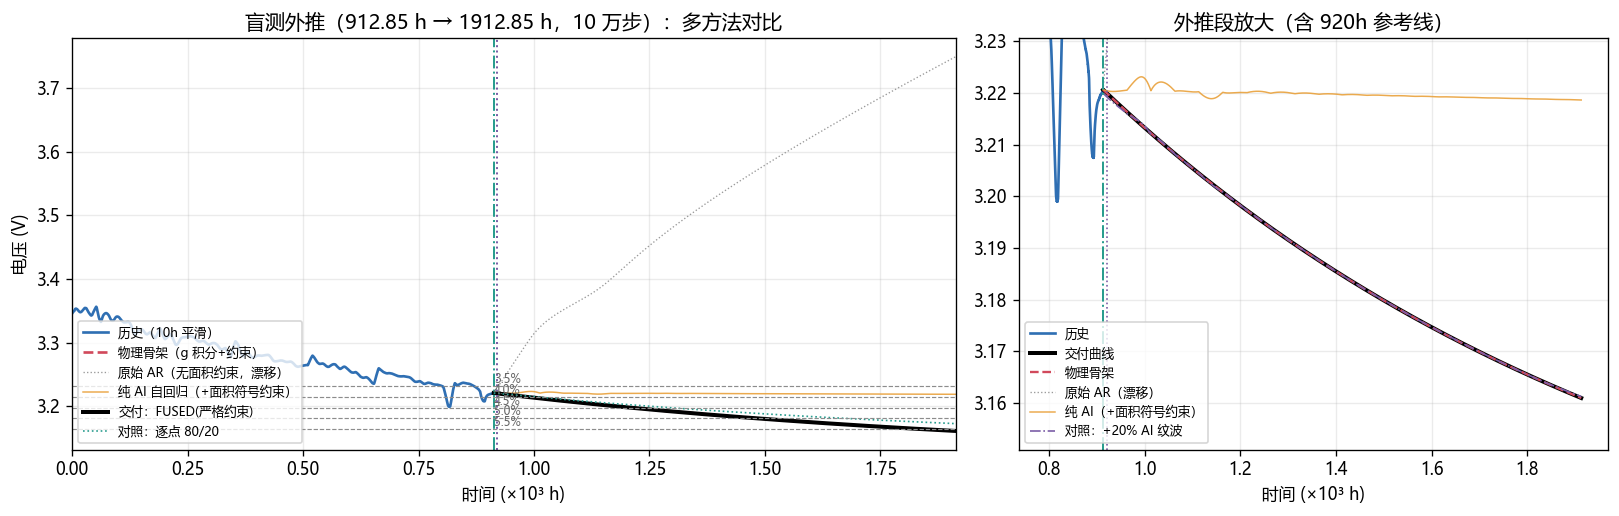

已保存: C:\Users\YOGA\Desktop\电池ai分析\预测输出\figures\fig05_最终外推曲线.png


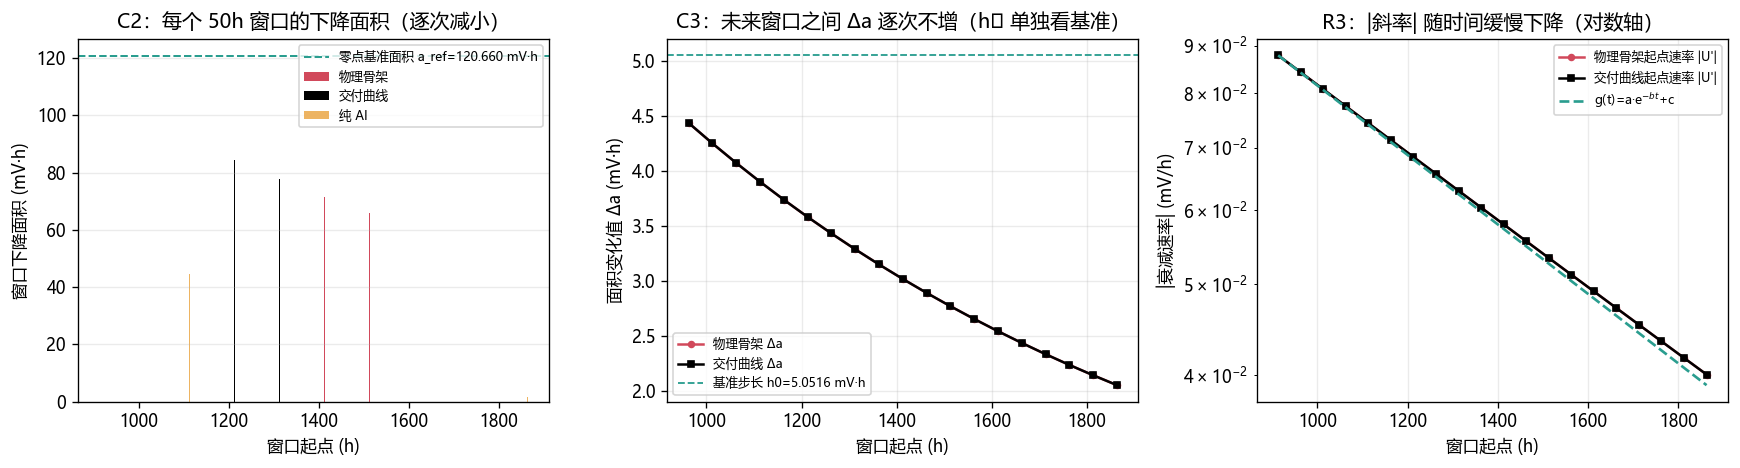

已保存: C:\Users\YOGA\Desktop\电池ai分析\预测输出\figures\fig06_面积链与速率.png


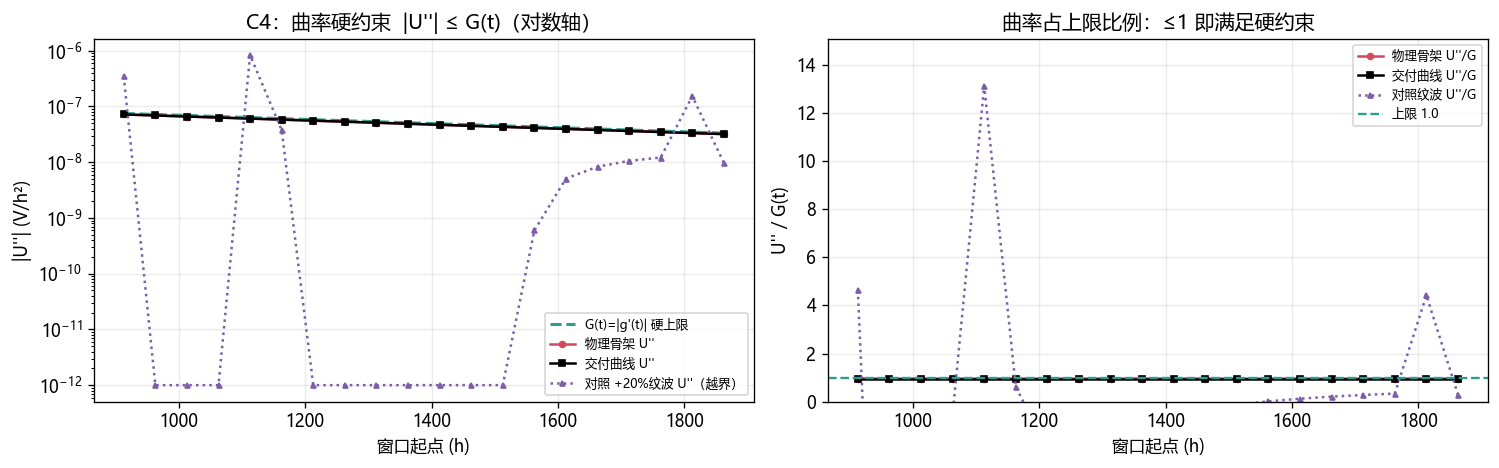

已保存: C:\Users\YOGA\Desktop\电池ai分析\预测输出\figures\fig07_曲率硬约束.png


In [21]:
# ------------------------------------------------
# 图 5：最终外推曲线（历史 + 物理骨架 + 纯AI + 80/20融合 + 对照）
# ------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.4), gridspec_kw=dict(width_ratios=[1.5, 1]))
ax = axes[0]
ax.plot(t[::20] / 1e3, u_s[::20], lw=1.6, color="#2f6fb3", label="历史（10h 平滑）")
ax.plot(T_FUSED / 1e3, BONE["u"], lw=1.6, color="#d1495b", ls="--", label="物理骨架（g 积分+约束）")
ax.plot(T_AI / 1e3, U_AI_RAW, lw=0.8, color="0.6", ls=":", label="原始 AR（无面积约束，漂移）")
ax.plot(T_AI / 1e3, U_AI, lw=0.9, color="#e9a13b", alpha=0.9, label="纯 AI 自回归（+面积符号约束）")
ax.plot(T_FUSED / 1e3, U_FUSED, lw=2.4, color="k", label=f"交付：{FUSED_DELIVERED_NAME}")
ax.plot(T_FUSED / 1e3, U_ELEM, lw=1.0, color="#2a9d8f", ls=":", label="对照：逐点 80/20")
ax.axvline(t0 / 1e3, color="#2a9d8f", ls="-.", lw=1.2)
ax.axvline(T_EXTRAP / 1e3, color="#7b5ea7", ls=":", lw=1.2)
for ft, uth in zip(RUL_FT_, RUL_UTH):
    ax.axhline(uth, color="0.55", lw=0.7, ls="--")
    ax.annotate(f"{ft}%", xy=(t0 / 1e3, uth), fontsize=7, color="0.4", va="bottom")
ax.set_xlabel("时间 (×10³ h)"); ax.set_ylabel("电压 (V)")
ax.set_title("盲测外推（912.85 h → 1912.85 h，10 万步）：多方法对比")
ax.legend(fontsize=7.5, loc="lower left"); ax.set_xlim(0, (t0 + N_STEPS_EXTRAP * DT) / 1e3)

ax = axes[1]
sl = T_FUSED >= t0 - 120
ax.plot(t[t >= t0 - 120] / 1e3, u_s[t >= t0 - 120], lw=1.6, color="#2f6fb3", label="历史")
ax.plot(T_FUSED[sl] / 1e3, U_FUSED[sl], lw=2.4, color="k", label="交付曲线")
ax.plot(T_FUSED[sl] / 1e3, BONE["u"][sl], lw=1.4, color="#d1495b", ls="--", label="物理骨架")
ax.plot(T_AI[sl] / 1e3, U_AI_RAW[sl], lw=0.8, color="0.6", ls=":", label="原始 AR（漂移）")
ax.plot(T_AI[sl] / 1e3, U_AI[sl], lw=0.9, color="#e9a13b", alpha=0.9, label="纯 AI（+面积符号约束）")
ax.plot(T_FUSED[sl] / 1e3, U_FUSE_WIGGLE[sl], lw=1.0, color="#7b5ea7", ls="-.",
        label="对照：+20% AI 纹波")
ax.axvline(t0 / 1e3, color="#2a9d8f", ls="-.", lw=1.2)
ax.axvline(T_EXTRAP / 1e3, color="#7b5ea7", ls=":", lw=1.0)
ax.set_xlabel("时间 (×10³ h)"); ax.set_ylim(min(U_FUSED.min(), U_FUSE_WIGGLE.min()) - 0.01,
                                            max(u_anchor, U_FUSE_WIGGLE.max()) + 0.01)
ax.set_title("外推段放大（含 920h 参考线）")
ax.legend(fontsize=7.5, loc="lower left")
fig.tight_layout()
print("已保存:", savefig(fig, "fig05_最终外推曲线"))

# ------------------------------------------------
# 图 6：面积微积分 —— 面积链 / 面积变化值 / 速率衰减
# ------------------------------------------------
_tw = t0 + np.arange(N_WIN_FUTURE) * SEG_H
_a_bone = BONE["achieved_mVh"]
_a_fuse = FUSED["achieved_mVh"]
_a_ai = A_AI

fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.0))
ax = axes[0]
w = 0.27
ax.bar(_tw - w, _a_bone, width=w * 0.95, color="#d1495b", label="物理骨架")
ax.bar(_tw, _a_fuse, width=w * 0.95, color="k", label="交付曲线")
ax.bar(_tw + w, np.clip(_a_ai, 0, None), width=w * 0.95, color="#e9a13b", alpha=0.8, label="纯 AI")
ax.axhline(BL["a_ref"], color="#2a9d8f", ls="--", lw=1.2, label=f"零点基准面积 a_ref={BL['a_ref']:.3f} mV·h")
ax.set_xlabel("窗口起点 (h)"); ax.set_ylabel("窗口下降面积 (mV·h)")
ax.set_title("C2：每个 50h 窗口的下降面积（逐次减小）")
ax.legend(fontsize=7.5); ax.grid(axis="x", visible=False)

ax = axes[1]
_h_bone = -np.diff(_a_bone)          # 未来窗口内部 Δa（C3 的核对对象）
_h_fuse = -np.diff(_a_fuse)
_tw_h = _tw[1:]
ax.plot(_tw_h, _h_bone, "o-", ms=3.5, color="#d1495b", label="物理骨架 Δa")
ax.plot(_tw_h, _h_fuse, "s-", ms=3.5, color="k", label="交付曲线 Δa")
ax.axhline(H0_WIN, color="#2a9d8f", ls="--", lw=1.1, label=f"基准步长 h0={H0_WIN:.4f} mV·h")
ax.set_xlabel("窗口起点 (h)"); ax.set_ylabel("面积变化值 Δa (mV·h)")
ax.set_title("C3：未来窗口之间 Δa 逐次不增（h₀ 单独看基准）")
ax.legend(fontsize=7.5)

ax = axes[2]
_ar, __, _r_fuse = window_quadratic_stats(U_FUSED, 0)
ax.semilogy(_tw, BONE["g0"] * 1e3, "o-", ms=3.5, color="#d1495b", label="物理骨架起点速率 |U'|")
ax.semilogy(_tw, _r_fuse, "s-", ms=3.5, color="k", label="交付曲线起点速率 |U'|")
ax.semilogy(_tw, GFIT["g"](_tw) * 1e3, "--", lw=1.6, color="#2a9d8f", label="g(t)=a·e$^{-bt}$+c")
ax.set_xlabel("窗口起点 (h)"); ax.set_ylabel("|衰减速率| (mV/h)")
ax.set_title("R3：|斜率| 随时间缓慢下降（对数轴）")
ax.legend(fontsize=7.5)
fig.tight_layout()
print("已保存:", savefig(fig, "fig06_面积链与速率"))

# ------------------------------------------------
# 图 7：曲率硬约束核对（C4）
# ------------------------------------------------
Gcap_w = GFIT["G"](_tw)
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.0))
ax = axes[0]
ax.semilogy(_tw, Gcap_w, "--", lw=1.8, color="#2a9d8f", label="G(t)=|g'(t)| 硬上限")
ax.semilogy(_tw, BONE["u2"], "o-", ms=3.5, color="#d1495b", label="物理骨架 U''")
ax.semilogy(_tw, FUSED["u2"], "s-", ms=3.5, color="k", label="交付曲线 U''")
ax.semilogy(_tw, np.maximum(_w_u2, 1e-12), "^:", ms=3, color="#7b5ea7", label="对照 +20%纹波 U''（越界）")
ax.set_xlabel("窗口起点 (h)"); ax.set_ylabel("|U''| (V/h²)")
ax.set_title("C4：曲率硬约束  |U''| ≤ G(t)（对数轴）")
ax.legend(fontsize=7.5)

ax = axes[1]
ax.plot(_tw, BONE["u2"] / Gcap_w, "o-", ms=3.5, color="#d1495b", label="物理骨架 U''/G")
ax.plot(_tw, FUSED["u2"] / Gcap_w, "s-", ms=3.5, color="k", label="交付曲线 U''/G")
ax.plot(_tw, _w_u2 / Gcap_w, "^:", ms=3, color="#7b5ea7", label="对照纹波 U''/G")
ax.axhline(1.0, color="#2a9d8f", ls="--", lw=1.4, label="上限 1.0")
ax.set_xlabel("窗口起点 (h)"); ax.set_ylabel("U'' / G(t)")
ax.set_title("曲率占上限比例：≤1 即满足硬约束")
ax.legend(fontsize=7.5); ax.set_ylim(bottom=0)
fig.tight_layout()
print("已保存:", savefig(fig, "fig07_曲率硬约束"))

RUL 预测（盲测，起点 = 数据末点 912.85 h；未穿越 = 1000 h 外推窗内未达阈值/删失）
     FT(%)   U_th(V)      物理骨架    纯AI自回归    交付融合曲线对照:逐点80/20
       3.5    3.2311       0.0       0.0       0.0       0.0
       4.0    3.2144      73.1       未穿越      73.1      95.1
       4.5    3.1977     295.0       未穿越     295.0     379.7
       5.0    3.1809     567.3       未穿越     567.4     755.6
       5.5    3.1642     919.2       未穿越     919.2       未穿越

用户指定的 920 h 参考点（数据末点之后 7.15 h）：
  物理骨架         U(920h) = 3.22000 V, 局部斜率 ≈ -0.0873 mV/h
  纯AI自回归       U(920h) = 3.22043 V, 局部斜率 ≈ -0.0208 mV/h
  交付融合曲线       U(920h) = 3.22000 V, 局部斜率 ≈ -0.0873 mV/h
  对照:逐点80/20   U(920h) = 3.22009 V, 局部斜率 ≈ -0.0740 mV/h
  物理骨架 g(920h) = 0.08732 mV/h（由指数拟合直接给出）


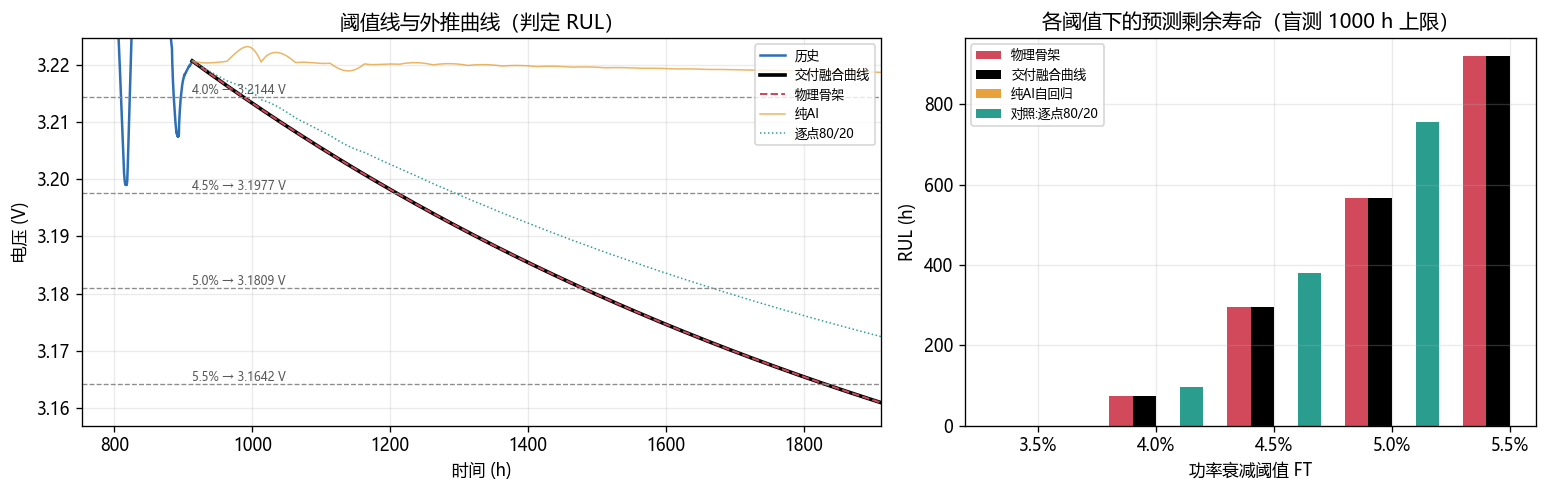


已保存: C:\Users\YOGA\Desktop\电池ai分析\预测输出\figures\fig08_RUL阈值与穿越.png


In [22]:
# ============================================================
# 9. 剩余寿命 RUL：从各曲线求阈值穿越时刻（带 5h 去抖）
# ============================================================
def rul_from_curve(t_arr, u_arr, uth, t_start, debounce_h=CROSS_DEBOUNCE_H):
    """首次"持续 debounce_h 低于阈值"的时刻 → RUL(h)；未穿越返回 None（删失）。"""
    n_deb = max(1, int(round(debounce_h / DT)))
    below = np.asarray(u_arr, float) < uth
    if len(below) < n_deb:
        return None, None
    c = np.convolve(below.astype(np.int32), np.ones(n_deb, np.int32), mode="valid")
    idx = np.where(c >= n_deb)[0]
    if len(idx) == 0:
        return None, None
    i = int(idx[0])
    return float(t_arr[i] - t_start), i


CURVES = {"物理骨架": (T_FUSED, BONE["u"]),
          "纯AI自回归": (T_AI, U_AI),
          "交付融合曲线": (T_FUSED, U_FUSED),
          "对照:逐点80/20": (T_FUSED, U_ELEM)}

rows = []
for ft, uth in zip(RUL_FT_, RUL_UTH):
    row = {"FT(%)": ft, "U_th(V)": uth}
    for name, (tt_, uu_) in CURVES.items():
        r, i = rul_from_curve(tt_, uu_, uth, t0)
        if r is not None and r < 0:
            r = 0.0                                   # 起点已低于阈值 → 视为 RUL=0（已失效）
        row[name] = r
    rows.append(row)
RUL_TABLE = pd.DataFrame(rows)
print("RUL 预测（盲测，起点 = 数据末点 912.85 h；未穿越 = 1000 h 外推窗内未达阈值/删失）")


def _print_rul_table(df):
    """分列格式化打印（FT 1 位、U_th 4 位、RUL 1 位；None → 未穿越）。"""
    cols = list(df.columns)
    wid = {c: max(len(c), 10) for c in cols}
    print("".join(f"{c:>{wid[c]}}" for c in cols))
    for _, r in df.iterrows():
        line = ""
        for c in cols:
            v = r[c]
            if v is None or (isinstance(v, float) and np.isnan(v)):
                s = "未穿越"
            elif c == "U_th(V)":
                s = f"{v:.4f}"
            elif c == "FT(%)":
                s = f"{v:.1f}"
            else:
                s = f"{v:.1f}"
            line += f"{s:>{wid[c]}}"
        print(line)


_print_rul_table(RUL_TABLE)

# 920 h 处的电压 / 斜率
print("\n用户指定的 920 h 参考点（数据末点之后 7.15 h）：")
for name, (tt_, uu_) in CURVES.items():
    u920 = float(np.interp(T_EXTRAP, tt_, uu_))
    sl920 = float((np.interp(T_EXTRAP + 1.0, tt_, uu_) - u920)) * 1e3     # mV/h
    print(f"  {name:12s} U(920h) = {u920:.5f} V, 局部斜率 ≈ {sl920:+.4f} mV/h")
print(f"  物理骨架 g(920h) = {float(GFIT['g'](T_EXTRAP))*1e3:.5f} mV/h（由指数拟合直接给出）")

# ------------------------------------------------
# 图 8：RUL 阈值与穿越时刻
# ------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.2), gridspec_kw=dict(width_ratios=[1.4, 1]))
ax = axes[0]
sl = T_FUSED >= t0 - 150
ax.plot(t[t >= t0 - 150], u_s[t >= t0 - 150], lw=1.5, color="#2f6fb3", label="历史")
ax.plot(T_FUSED[sl], U_FUSED[sl], lw=2.2, color="k", label="交付融合曲线")
ax.plot(T_FUSED[sl], BONE["u"][sl], lw=1.2, ls="--", color="#d1495b", label="物理骨架")
ax.plot(T_AI[sl], U_AI[sl], lw=0.9, alpha=0.8, color="#e9a13b", label="纯AI")
ax.plot(T_FUSED[sl], U_ELEM[sl], lw=0.9, ls=":", color="#2a9d8f", label="逐点80/20")
for ft, uth in zip(RUL_FT_, RUL_UTH):
    ax.axhline(uth, color="0.55", lw=0.8, ls="--")
    ax.annotate(f"{ft}% → {uth:.4f} V", xy=(t0, uth), fontsize=7, color="0.35", va="bottom")
ax.set_xlabel("时间 (h)"); ax.set_ylabel("电压 (V)")
ax.set_title("阈值线与外推曲线（判定 RUL）")
ax.legend(fontsize=7.5, loc="upper right"); ax.set_xlim(t0 - 160, t0 + 1000)
ax.set_ylim(min(U_FUSED.min(), U_ELEM.min()) - 0.004, u_anchor + 0.004)

ax = axes[1]
xs = np.arange(len(RUL_FT_))
wbar = 0.2
for j, (name, color) in enumerate(zip(["物理骨架", "交付融合曲线", "纯AI自回归", "对照:逐点80/20"],
                                      ["#d1495b", "k", "#e9a13b", "#2a9d8f"])):
    vals = [np.nan if RUL_TABLE[name][i] is None else RUL_TABLE[name][i] for i in range(len(RUL_FT_))]
    ax.bar(xs + (j - 1.5) * wbar, vals, width=wbar, color=color, label=name)
ax.set_xticks(xs); ax.set_xticklabels([f"{f}%" for f in RUL_FT_])
ax.set_xlabel("功率衰减阈值 FT"); ax.set_ylabel("RUL (h)")
ax.set_title("各阈值下的预测剩余寿命（盲测 1000 h 上限）")
ax.legend(fontsize=7.5)
fig.tight_layout()
print("\n已保存:", savefig(fig, "fig08_RUL阈值与穿越"))

In [23]:
# ============================================================
# 10. 可复用全流程 + 盲测回填检验
# ============================================================
def run_pipeline(hist, origin_h, tag="", epochs=EPOCHS, n_steps=N_STEPS_EXTRAP, seed=SEED, verbose=True):
    """在 origin_h 处截断历史，跑完整流程（训练→g→面积→AR→融合→RUL），返回结果字典。

    hist: load_and_prepare 的输出（全量数组）
    """
    i_end = int(round(origin_h / DT))
    sl = slice(0, i_end + 1)
    u, I, T, RH = hist["u_s"][sl], hist["I_s"][sl], hist["T_s"][sl], hist["RH_s"][sl]
    tt = hist["t"][sl]
    t_ref = float(tt[-1])
    n_win = n_steps // SEG_STEPS
    if verbose:
        print(f"\n===== {tag}：起点 {t_ref:.2f} h，历史 {len(u):,} 点，外推 {n_steps} 步 "
              f"({n_steps*DT:.0f} h, {n_win} 窗口) =====")

    # ① 150h 趋势曲线 → 段速率 → 指数 g（g 与面积基准必须同源，否则面积链与曲率约束互相矛盾）
    trend = compute_trend(u)
    seg = segment_decay_rates(trend)
    gf = fit_exp_decay(seg)
    g_start = float(gf["g"](t_ref))
    gf_end = lambda _tt: gf["G"](np.asarray(_tt, float) + SEG_H)   # 区间内最小曲率上限 = 窗口末端 G
    bl = compute_area_baseline(trend)
    phys = phys_window_areas(gf, t_ref, n_win)
    a_ref = float(max(bl["a_emp"], phys["a_last"]))
    bl["a_ref"] = a_ref

    F, st = feature_matrix(u, I, T, RH, tt, t_ref)
    X, y, tau, sig = build_windows(F, u, tt)
    model_b, log_b = train_model(X, y, tau, sig, epochs=epochs, seed=seed, verbose=False)

    # ② 物理骨架：由 g 直接给出的面积下界（U''=G，即自然指数衰减）
    bone = reconstruct_chain(phys["lo"] * (1.0 + 1e-6), float(u[-1]), g_start, t_ref, gf_end)

    u_ai_raw, t_ai = ar_rollout(model_b, st, sig, u_hist=u[-SEQ:], t_hist=tt[-SEQ:],
                                I_last=I[-1], T_last=T[-1], RH_last=RH[-1],
                                dI_last=float(np.gradient(I, DT)[-1]),
                                dT_last=float(np.gradient(T, DT)[-1]),
                                n_steps=n_steps, verbose=False)
    u_ai, _n_fix, _off = enforce_declining_area(u_ai_raw, SEG_STEPS, margin_mV=0.10)
    a_ai_signed, _, _ = window_areas(u_ai, start=0, n_win=n_win)
    a_ai = -a_ai_signed * 1e3
    # ③ 80/20：物理锚定可行带 + AI 决定带内 20% 位置 → 投影 → 重建
    band = phys["hi"] - phys["lo"]
    a_ai_pos = np.clip((a_ai - phys["lo"]) / np.maximum(band, 1e-12), 0.0, 1.0)
    a_fuse_band = phys["lo"] + W_AI * a_ai_pos * band
    a_proj = project_area_chain(a_fuse_band, phys["lo"], phys["hi"], a_ref)
    fused = reconstruct_chain(a_proj, float(u[-1]), g_start, t_ref, gf_end)

    I_ref = float(np.median(I[-1000:]))
    P_init = float(np.mean(u[:int(P_INIT_H / DT)] * I[:int(P_INIT_H / DT)]))
    uths = [P_init * (1 - f / 100.0) / I_ref for f in RUL_FT_]
    ruls = {"Uth": uths}
    for name, (tt_, uu_) in {"bone": (bone["t"], bone["u"]),
                             "ai": (t_ai, u_ai),
                             "fused": (fused["t"], fused["u"])}.items():
        ruls[name] = [rul_from_curve(tt_, uu_, uu_th, t_ref)[0] for uu_th in uths]
    if verbose:
        print(f"  g(t₀)={g_start*1e3:.5f} mV/h, a_ref={bl['a_ref']:.4f} mV·h, "
              f"验证RMSE={log_b['val_rmse_mV'][log_b['best_epoch']-1]:.3f} mV/步")
        print(f"  终点: bone {bone['u'][-1]:.5f}, fused {fused['u'][-1]:.5f}, ai {u_ai[-1]:.5f} V")
        print("  RUL:", {f"{f}%": (None if ruls['fused'][i] is None else round(ruls['fused'][i], 1))
                         for i, f in enumerate(RUL_FT_)})
    return dict(t_ref=t_ref, u_hist=u.copy(), t_hist=tt.copy(), gf=gf, seg=seg, bl=bl,
                bone=bone, fused=fused, u_ai=u_ai, u_ai_raw=u_ai_raw, t_ai=t_ai, ruls=ruls,
                P_init=P_init, I_ref=I_ref, log=log_b, a_ai=a_ai, model=model_b)


# ---------------- 检验 A：内测回填（700 h → 912.85 h，有真值） ----------------
BT_A_H, BT_A_STEPS = 700.0, int(round((t_end - 700.0) / DT))
BT_A = run_pipeline(data, BT_A_H, tag="检验A 内测回填 700h", n_steps=BT_A_STEPS)
_truth_A_t = t[t >= BT_A_H]
_truth_A_u = u_s[t >= BT_A_H]
for name in ["bone", "fused", "ai"]:
    key = "u" if name != "ai" else "u_ai"
    tt_ = BT_A["t_ai"] if name == "ai" else BT_A["bone"]["t"]
    uu_ = BT_A["u_ai"] if name == "ai" else BT_A[f"{name}"]["u"]
    interp = np.interp(_truth_A_t, tt_, uu_)
    err = interp - _truth_A_u
    print(f"  [{name:5s}] 212.85h 外推 vs 真值: RMSE={np.sqrt(np.mean(err**2))*1e3:7.3f} mV, "
          f"终点误差={err[-1]*1e3:+7.3f} mV, 最大|误差|={np.max(np.abs(err))*1e3:7.3f} mV")


===== 检验A 内测回填 700h：起点 700.00 h，历史 70,001 点，外推 21285 步 (213 h, 4 窗口) =====
  g(t₀)=0.10245 mV/h, a_ref=137.5117 mV·h, 验证RMSE=0.012 mV/步
  终点: bone 3.23014, fused 3.23014, ai 3.23138 V
  RUL: {'3.5%': None, '4.0%': None, '4.5%': None, '5.0%': None, '5.5%': None}
  [bone ] 212.85h 外推 vs 真值: RMSE= 11.304 mV, 终点误差= +9.511 mV, 最大|误差|= 38.605 mV
  [fused] 212.85h 外推 vs 真值: RMSE= 11.304 mV, 终点误差= +9.511 mV, 最大|误差|= 38.605 mV
  [ai   ] 212.85h 外推 vs 真值: RMSE= 11.930 mV, 终点误差=+10.746 mV, 最大|误差|= 39.347 mV



===== 检验B 盲测回填 660h：起点 660.00 h，历史 66,001 点，外推 100000 步 (1000 h, 20 窗口) =====
  g(t₀)=0.11930 mV/h, a_ref=157.5827 mV·h, 验证RMSE=0.010 mV/步
  终点: bone 3.16298, fused 3.16298, ai 3.24179 V
  RUL: {'3.5%': 198.0, '4.0%': 365.6, '4.5%': 553.1, '5.0%': 765.8, '5.5%': None}

载入完整记录用于事后打分: C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\FC1.csv
真值区间 660.00 ~ 1154.21 h（49,422 点）
  [bone ] 外推 vs 真值: RMSE=  13.646 mV, 终点误差= -11.339 mV, 最大|误差|=  39.667 mV
  [fused] 外推 vs 真值: RMSE=  13.646 mV, 终点误差= -11.339 mV, 最大|误差|=  39.667 mV
  [ai   ] 外推 vs 真值: RMSE=  18.271 mV, 终点误差= +30.669 mV, 最大|误差|=  44.426 mV

660h 盲测 RUL 回填（未穿越 = 1000h 内未达阈值/删失）
     FT(%)   U_th(V)  真值RUL(h)预测_bone(h)预测_fused(h)  预测_ai(h)
       3.5    3.2292     144.2     198.0      198.0       未穿越
       4.0    3.2125     150.1     365.6      365.6       未穿越
       4.5    3.1957       未穿越     553.1      553.1       未穿越
       5.0    3.1790       未穿越     765.8      765.8      

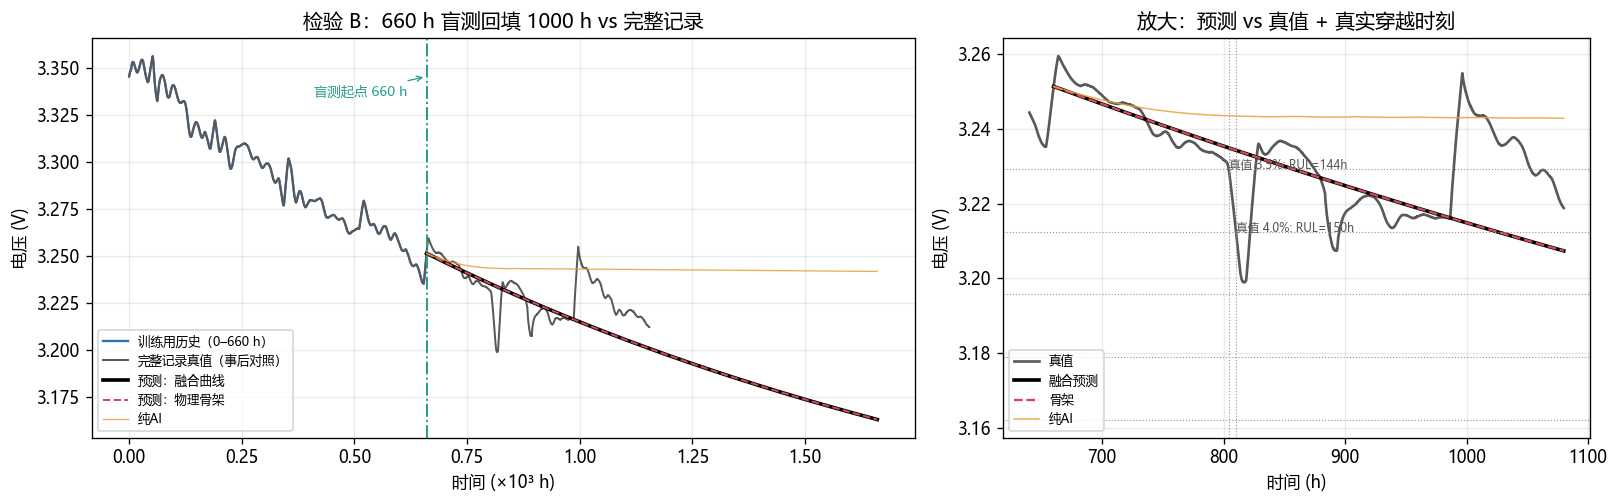


已保存: C:\Users\YOGA\Desktop\电池ai分析\预测输出\figures\fig09_盲测回填验证.png


In [24]:
# ---------------- 检验 B：660 h 盲测回填（用 FC1 完整记录的真值打分） ----------------
BT_B = run_pipeline(data, BT_ORIGIN_H, tag="检验B 盲测回填 660h")

FULL_PATH = next((p for p in FULL_DATA_CANDIDATES if p.exists()), None)
if FULL_PATH is None:
    print("\n[跳过] 未找到 FC1 完整记录，无法做含真值的盲测打分。")
else:
    print(f"\n载入完整记录用于事后打分: {FULL_PATH}")
    FULL = load_and_prepare(FULL_PATH)
    tf_, uf_ = FULL["t"], FULL["u_s"]
    m_ov = (tf_ >= BT_B["t_ref"]) & (tf_ <= BT_B["t_ref"] + N_STEPS_EXTRAP * DT)
    truth_t, truth_u = tf_[m_ov], uf_[m_ov]
    print(f"真值区间 {truth_t[0]:.2f} ~ {truth_t[-1]:.2f} h（{len(truth_t):,} 点）")

    # 外推精度（覆盖真值的部分）
    for name, (tt_, uu_) in {"bone": (BT_B["bone"]["t"], BT_B["bone"]["u"]),
                             "fused": (BT_B["fused"]["t"], BT_B["fused"]["u"]),
                             "ai": (BT_B["t_ai"], BT_B["u_ai"])}.items():
        pr = np.interp(truth_t, tt_, uu_)
        e = pr - truth_u
        print(f"  [{name:5s}] 外推 vs 真值: RMSE={np.sqrt(np.mean(e**2))*1e3:8.3f} mV, "
              f"终点误差={e[-1]*1e3:+8.3f} mV, 最大|误差|={np.max(np.abs(e))*1e3:8.3f} mV")

    # 真实 RUL（用同一套阈值 + 同一去抖）
    uf_fut = uf_[tf_ >= BT_B["t_ref"]]
    tf_fut = tf_[tf_ >= BT_B["t_ref"]]
    rows_b = []
    for ft, uth in zip(RUL_FT_, BT_B["ruls"]["Uth"]):
        true_rul, _ = rul_from_curve(tf_fut, uf_fut, uth, BT_B["t_ref"])
        pred = {k: BT_B["ruls"][k][len(rows_b)] for k in ("bone", "fused", "ai")}
        rows_b.append({"FT(%)": ft, "U_th(V)": uth, "真值RUL(h)": true_rul, **{
            f"预测_{k}(h)": v for k, v in pred.items()}})
    BT_RUL = pd.DataFrame(rows_b)
    print("\n660h 盲测 RUL 回填（未穿越 = 1000h 内未达阈值/删失）")
    _print_rul_table(BT_RUL)

    # IEEE PHM 2014 官方打分（%Err<0 = 提前预测失效，惩罚更重；A_FT∈(0,1]）、ScoreRUL = 各档均值
    def score_A(pred, true):
        if pred is None or true is None:
            return np.nan
        e = (pred - true) / true * 100.0
        return float(np.exp(-math.log(0.5) * e / 5.0)) if e <= 0 \
            else float(np.exp(+math.log(0.5) * e / 20.0))

    for k in ("bone", "fused", "ai"):
        cols_t, cols_p = "真值RUL(h)", f"预测_{k}(h)"
        scs = [score_A(BT_RUL[cols_p][i], BT_RUL[cols_t][i]) for i in range(len(BT_RUL))]
        valid = [s for s in scs if not np.isnan(s)]
        print(f"  打分 A_FT[{k}] = {[f'{s:.3f}' if not np.isnan(s) else '—' for s in scs]}"
              f"  → ScoreRUL = {np.mean(valid):.3f}" if valid else f"  打分 A_FT[{k}] 全部删失")

    # ------------------------------------------------
    # 图 9：660h 盲测回填 vs 真值
    # ------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.3), gridspec_kw=dict(width_ratios=[1.4, 1]))
    ax = axes[0]
    ax.plot(t[:int(BT_ORIGIN_H / DT) + 1:20] / 1e3, BT_B["u_hist"][::20], lw=1.4, color="#2f6fb3",
            label="训练用历史（0–660 h）")
    ax.plot(tf_ / 1e3, uf_, lw=1.2, color="0.35", label="完整记录真值（事后对照）")
    ax.plot(BT_B["fused"]["t"] / 1e3, BT_B["fused"]["u"], lw=2.2, color="k", label="预测：融合曲线")
    ax.plot(BT_B["bone"]["t"] / 1e3, BT_B["bone"]["u"], lw=1.2, ls="--", color="#d1495b", label="预测：物理骨架")
    ax.plot(BT_B["t_ai"] / 1e3, BT_B["u_ai"], lw=0.8, color="#e9a13b", alpha=0.85, label="纯AI")
    ax.axvline(BT_ORIGIN_H / 1e3, color="#2a9d8f", ls="-.", lw=1.2)
    ax.annotate("盲测起点 660 h", xy=(BT_ORIGIN_H / 1e3, uf_[0]), xytext=(BT_ORIGIN_H / 1e3 - 0.25, uf_[0] - 0.01),
                fontsize=8, color="#2a9d8f", arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=0.8))
    ax.set_xlabel("时间 (×10³ h)"); ax.set_ylabel("电压 (V)")
    ax.set_title("检验 B：660 h 盲测回填 1000 h vs 完整记录")
    ax.legend(fontsize=7.5, loc="lower left")

    ax = axes[1]
    zl = (tf_ >= BT_ORIGIN_H - 20) & (tf_ <= BT_ORIGIN_H + 420)
    ax.plot(tf_[zl], uf_[zl], lw=1.6, color="0.35", label="真值")
    mz = BT_B["fused"]["t"] <= BT_ORIGIN_H + 420
    ax.plot(BT_B["fused"]["t"][mz], BT_B["fused"]["u"][mz], lw=2.2, color="k", label="融合预测")
    ax.plot(BT_B["bone"]["t"][mz], BT_B["bone"]["u"][mz], lw=1.4, ls="--", color="#d1495b", label="骨架")
    ax.plot(BT_B["t_ai"][mz], BT_B["u_ai"][mz], lw=0.9, color="#e9a13b", alpha=0.85, label="纯AI")
    for ft, uth, tr in zip(RUL_FT_, BT_B["ruls"]["Uth"], [BT_RUL["真值RUL(h)"][i] for i in range(len(RUL_FT_))]):
        ax.axhline(uth, color="0.6", lw=0.7, ls=":")
        if tr is not None:
            ax.axvline(BT_ORIGIN_H + tr, color="0.6", lw=0.7, ls=":")
            ax.annotate(f"真值 {ft}%: RUL={tr:.0f}h", xy=(BT_ORIGIN_H + tr, uth), fontsize=7, color="0.35")
    ax.set_xlabel("时间 (h)"); ax.set_ylabel("电压 (V)")
    ax.set_title("放大：预测 vs 真值 + 真实穿越时刻")
    ax.legend(fontsize=7.5, loc="lower left")
    fig.tight_layout()
    print("\n已保存:", savefig(fig, "fig09_盲测回填验证"))

In [25]:
# ============================================================
# 11. 结果落盘（CSV / JSON）+ 最终汇总打印
# ============================================================
# 1) 外推曲线
_curve_df = pd.DataFrame({
    "t_h": T_FUSED,
    "U_fused_V": U_FUSED,
    "U_bone_V": BONE["u"],
    "U_ai_V": U_AI,
    "U_perpoint_80_20_V": U_ELEM,
})
_curve_df.to_csv(OUT_DIR / "外推曲线.csv", index=False, float_format="%.8f", encoding="utf-8-sig")

# 2) 面积链与约束
_area_df = pd.DataFrame({
    "window": np.arange(1, N_WIN_FUTURE + 1),
    "t_start_h": t0 + np.arange(N_WIN_FUTURE) * SEG_H,
    "target_phys_mVh": BONE["achieved_mVh"],
    "ai_mVh": A_AI,
    "fuse_raw_mVh": A_FUSE_RAW,
    "fuse_band_mVh": A_FUSE_BAND,
    "projected_mVh": A_PROJ,
    "delta_mVh": -np.diff(np.concatenate([[BL["a_ref"]], A_PROJ])),
    "u2_phys_curv": BONE["u2"],
    "G_cap": GFIT["G_end"](t0 + np.arange(N_WIN_FUTURE) * SEG_H),
    "baseline_a_ref": BL["a_ref"],
    "band_lo": PHYS["lo"],
    "band_hi": PHYS["hi"],
})
_area_df.to_csv(OUT_DIR / "面积与约束.csv", index=False, float_format="%.8f", encoding="utf-8-sig")

# 3) RUL 汇总
RUL_TABLE.to_csv(OUT_DIR / "RUL汇总.csv", index=False, float_format="%.4f", encoding="utf-8-sig")

# 4) 盲测回填
try:
    BT_RUL.to_csv(OUT_DIR / "盲测回填.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
except NameError:
    pass

# 5) 训练日志
json.dump({"train_log": {k: (v if not isinstance(v, np.ndarray) else v.tolist()) for k, v in train_log.items()},
           "gfit": {"a": float(GFIT["a"]), "b": float(GFIT["b"]), "c": float(GFIT["c"]), "rmse": float(GFIT["rmse"]),
                    "g_t0_mVh": float(G0_SLOPE * 1e3), "G_t0": float(G0_CURV), "segment_rates": seg_df["rate"].tolist()},
           "area_baseline": {k: (v if not isinstance(v, np.ndarray) else v.tolist())
                             for k, v in BL.items() if isinstance(v, (int, float, list, np.ndarray))},
           "config": {"DT": DT, "SEG_H": SEG_H, "SEQ": SEQ, "EPOCHS": EPOCHS, "HIDDEN": HIDDEN,
                      "T_EXTRAP": T_EXTRAP, "N_STEPS_EXTRAP": N_STEPS_EXTRAP, "W_PHYS": W_PHYS, "W_AI": W_AI,
                      "LAMBDA_TIME": LAMBDA_TIME, "ALLOW_AI_RIPPLE": bool(ALLOW_AI_RIPPLE),
                      "P_INIT_W": P_INIT, "I_REF_A": I_REF, "u_anchor": float(u_anchor),
                      "t_end_h": float(t_end), "delivered_curve": FUSED_DELIVERED_NAME}},
          open(OUT_DIR / "train_log.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

print(f"\n所有产物已保存到: {OUT_DIR}")
print(f"  图片目录: {FIG_DIR}")
for _f in sorted(FIG_DIR.glob("*.png")):
    print("   -", _f.name)

# ------------------------------------------------------------
# 终端汇总（直接回答用户需求）
# ------------------------------------------------------------
print("\n" + "=" * 78)
print("最终汇总（盲测起点 %.2f h，外推 %d 步 = %.0f h）" % (t0, N_STEPS_EXTRAP, N_STEPS_EXTRAP * DT))
print("=" * 78)
print(f"历史末电压 u_anchor = {u_anchor:.5f} V  |  P_init(首10h) = {P_INIT:.3f} W  |  I_ref = {I_REF:.3f} A")
print(f"指数定标: g(t)={GFIT['a']:.6g}·e^(-{GFIT['b']:.6g}t)+{GFIT['c']:.3g}  "
      f"(RMSE={GFIT['rmse']*1e3:.4f} mV/h)")
print(f"外推初斜率 g(920h) = {G0_SLOPE*1e3:.5f} mV/h   |  曲率上限 G(920h) = {G0_CURV:.4e} V/h²")
print(f"零点基准面积 a_ref = {BL['a_ref']:.4f} mV·h  (≈ {2*BL['a_ref']/SEG_H:.4f} mV/50h)；"
      f"经验均值 a_emp={BL['a_emp']:.4f}，与 g 同源的 a_last_phys={BL['a_last_phys']:.4f} mV·h")
for _i, _row in RUL_TABLE.iterrows():
    _v = ""
    for _k in ["物理骨架", "纯AI自回归", "交付融合曲线"]:
        _x = _row[_k]
        _v += f" | {_k}={'删失' if pd.isna(_x) else f'{_x:.1f} h'}"
    print(f"  FT={_row['FT(%)']}%: U_th={_row['U_th(V)']:.4f} V{_v}")
print(f"\n交付曲线 {FUSED_DELIVERED_NAME}: 终点 {U_FUSED[-1]:.5f} V（下降 {(u_anchor-U_FUSED[-1])*1e3:.2f} mV）")
for _nm, _rep in [("物理骨架", REP_BONE), ("交付融合", REP_FUSED)]:
    _ok = all(_rep[k] == 1.0 for k in _rep if str(k).startswith(("C1", "C2_", "C2b", "C3", "C4_曲率", "C5")))
    print(f"约束检查[{_nm}]: 全部满足={_ok} | max|U''|/G = {_rep['C4_最大/G']:.3f}")
print("=" * 78)


所有产物已保存到: C:\Users\YOGA\Desktop\电池ai分析\预测输出
  图片目录: C:\Users\YOGA\Desktop\电池ai分析\预测输出\figures
   - fig01_历史数据总览.png
   - fig02_训练曲线与一步检验.png
   - fig03_指数衰减拟合.png
   - fig04_纯AI自回归对比.png
   - fig05_最终外推曲线.png
   - fig06_面积链与速率.png
   - fig07_曲率硬约束.png
   - fig08_RUL阈值与穿越.png
   - fig09_盲测回填验证.png
   - fig10_分位数回归标定.png
   - fig11_RUL概率分布直方图.png
   - fig12_RUL生存概率与分位数.png
   - fig13_不确定性量化_分位数带.png

最终汇总（盲测起点 912.85 h，外推 100000 步 = 1000 h）
历史末电压 u_anchor = 3.22063 V  |  P_init(首10h) = 235.060 W  |  I_ref = 70.202 A
指数定标: g(t)=0.00019181·e^(-0.000855358t)+2.03e-24  (RMSE=0.0452 mV/h)
外推初斜率 g(920h) = 0.08786 mV/h   |  曲率上限 G(920h) = 7.5148e-08 V/h²
零点基准面积 a_ref = 120.6604 mV·h  (≈ 4.8264 mV/50h)；经验均值 a_emp=120.6604，与 g 同源的 a_last_phys=112.9842 mV·h
  FT=3.5%: U_th=3.2311 V | 物理骨架=0.0 h | 纯AI自回归=0.0 h | 交付融合曲线=0.0 h
  FT=4.0%: U_th=3.2144 V | 物理骨架=73.1 h | 纯AI自回归=删失 | 交付融合曲线=73.1 h
  FT=4.5%: U_th=3.1977 V | 物理骨架=295.0 h | 纯AI自回归=删失 | 交付融合曲线=295.0 h
  FT=5.0%: U_th=3.1809 V | 物理骨架=567.3 h

In [26]:
import torch

# 假设模型实例化叫 model
# 把它保存到当前目录下
torch.save(model, '电池v1')
print("模型已成功保存！")

模型已成功保存！
